# Bézier fitting on Tool Hang: piecewise cubic curves on R³ × SO(3)

**Who this is for:** you know the Lift pipeline of `lift_bezier_fit.ipynb` (H22–H24) and the plan in `docs/H25_tool_hang_bezier_fit_plan.md`.

**What this notebook does:** it repeats the Lift chain on RoboMimic Tool Hang PH, and tests whether Bézier fits of the demos replay with success. This is the gate before policy training on Tool Hang.

**Outline**

- **Part 0 (H25.0).** Data check and absolute actions.
- **Part 1 (H25.1).** Replay reference.
- **Part 2 (H25.2).** Decoder with n phases.
- **Part 3 (H25.3).** Fits on `demo_0`.
- **Part 4 (H25.4).** Fits of all demos and replay.

In [1]:
import os

# Must be set before JAX starts. Small fits run faster on the CPU than with GPU call overhead.
os.environ["JAX_PLATFORMS"] = "cpu"

import jax

jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.transform import Rotation

from bezier_rfm.datasets.robomimic import arm_controller, demo_keys, load_demo_model, make_env

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/robomimic/datasets/tool_hang/ph"
SOURCE = DATA / "low_dim_v15.hdf5"
ABSOLUTE = DATA / "low_dim_abs.hdf5"
CONTROL_DT = 0.05
COLORS = {"close": "#d03b3b", "open": "#2a78d6", "bar": "#555555"}
CHECKS = {}


def record(name, value, limit, larger_passes=False):
    """Store one check result and print it.

    Args:
        name (str): Check name.
        value (float): Measured value.
        limit (float): Pass limit.
        larger_passes (bool): Whether values at or above the limit pass.

    Returns:
        None: Nothing.
    """
    ok = value >= limit if larger_passes else value <= limit
    CHECKS[name] = (float(value), limit, bool(ok))
    print(f"{name}: {value:.4g} (limit {'>=' if larger_passes else '<='} {limit:.4g}) {'pass' if ok else 'FAIL'}")


src_file = h5py.File(SOURCE, "r")
SRC = src_file["data"]
KEYS = demo_keys(SRC)
ENV_ARGS = json.loads(SRC.attrs["env_args"])
print(len(KEYS), "demos;", ENV_ARGS["env_name"], ENV_ARGS["env_version"])

200 demos; ToolHang 1.5.1


---
# Part 0. Data check and absolute actions (H25.0)

**Hypothesis H25.0.** The Python 3.12 stack runs Tool Hang, all demos have the same gripper event sequence, and the delta-to-absolute conversion passes the H15 checks.

The checks, agreed before the run:

| # | Check | Pass if |
| --- | --- | --- |
| 1 | env builds from `env_args`; stored state length is 1 + nq + nv | exact |
| 1 | one-step test on demo_0: from `states[t]`, `actions[t]` gives a smaller arm-joint error to `states[t+1]` than `actions[t±1]` | at ≥ 95 % of tested steps |
| 1 | open-loop delta replay of demo_0 | information only |
| 2 | gripper event sequence per demo | stop if the sequences differ |
| 3 | conversion vs controller-free formula; goal ranges; rotation-vector norm; other arrays unchanged | H15 limits: 1e-9 m, 1e-5 rad, 0.05·√3 m, 0.5·√3 rad, ≤ π, exact |
| 3 | rotation step between consecutive commands | stop if > π/2 |
| 4 | plots: N and phase durations, event timeline, rotation steps | — |

## 0.1 Environment and one-step test on demo_0

For each tested step t (every 10th step, plus the last), the cell resets to `states[t]`, steps once with `actions[t-1]`, `actions[t]`, and `actions[t+1]`, and measures the largest arm-joint difference to `states[t+1]`. The recorded action must give the smallest difference. The test is the H14 single-step test with more steps.

In [2]:
env = make_env(ENV_ARGS, SRC[f"{KEYS[0]}/obs"].keys())
demo0 = SRC[KEYS[0]]
load_demo_model(env, demo0)
model = env.env.sim.model
print("nq, nv:", model.nq, model.nv, "| state length:", demo0["states"].shape[1], "| N:", len(demo0["actions"]))

states0, actions0 = demo0["states"][:], demo0["actions"][:]
n0 = len(actions0)
arm_index = np.asarray(arm_controller(env).qpos_index)
tested = sorted(set(range(1, n0 - 1, 10)) | {n0 - 2})
errors = np.full((len(tested), 3), np.nan)
for i, t in enumerate(tested):
    for j, offset in enumerate((-1, 0, 1)):
        env.reset_to({"states": states0[t]})
        env.step(actions0[t + offset])
        # The flattened state is [time, qpos, qvel].
        errors[i, j] = np.abs(env.get_state()["states"][1:][arm_index] - states0[t + 1][1:][arm_index]).max()
best_is_recorded = errors.argmin(axis=1) == 1
record("0.1 fraction of steps where actions[t] is best", best_is_recorded.mean(), 0.95, larger_passes=True)
print(f"tested {len(tested)} steps; arm error with actions[t]: median {np.median(errors[:, 1]):.2e}, max {errors[:, 1].max():.2e} rad")
print("steps where a neighbor wins:", [t for t, b in zip(tested, best_is_recorded) if not b])

[robosuite WARNING] No private macro file found! (macros.py:53)


[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)


[robosuite WARNING] To setup, run: python /home/abbas/Projects/bezier-rfm/.venv/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)



============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'object', 'robot0_joint_pos', 'robot0_joint_vel', 'robot0_gripper_qpos', 'robot0_eef_pos', 'robot0_eef_quat', 'robot0_joint_pos_sin', 'robot0_joint_pos_cos', 'robot0_eef_quat_site']
using obs modality: rgb with keys: []


[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)


[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)


Created environment with name ToolHang
Action size is 7


nq, nv: 30 27 | state length: 58 | N: 681


0.1 fraction of steps where actions[t] is best: 1 (limit >= 0.95) pass
tested 69 steps; arm error with actions[t]: median 1.01e-10, max 4.31e-04 rad
steps where a neighbor wins: []


In [3]:
# Open-loop replay of the delta actions from the stored start (information only).
load_demo_model(env, demo0)
site = env.env.robots[0].eef_site_id["right"]
replay_pos = []
for a in actions0:
    env.step(a)
    env.env.sim.forward()
    replay_pos.append(env.env.sim.data.site_xpos[site].copy())
replay_pos = np.array(replay_pos)
recorded_pos = demo0["next_obs/robot0_eef_pos"][:]
print("open-loop delta replay success:", env.is_success()["task"])
print(f"grip-site distance to the recording: median {1e3 * np.median(np.linalg.norm(replay_pos - recorded_pos, axis=1)):.2f} mm, "
      f"final {1e3 * np.linalg.norm(replay_pos[-1] - recorded_pos[-1]):.2f} mm")

open-loop delta replay success: False
grip-site distance to the recording: median 0.64 mm, final 15.74 mm


## 0.2 Gripper events and phases

An event is an action index t where the gripper command changes: `g[t] != g[t-1]`. A change to +1 is a close and a change to −1 is an open. The phases are the intervals between the start, the events, and the end. Phase i has duration T_i = 0.05 × (number of action steps in the phase).

In [2]:
def events(gripper):
    """Return the event indices and names of one gripper command column.

    Args:
        gripper (np.ndarray): Gripper commands, shape (N,).

    Returns:
        tuple: Event indices (list of int) and names (tuple of str).
    """
    idx = np.flatnonzero(gripper[1:] != gripper[:-1]) + 1
    return idx.tolist(), tuple("close" if gripper[t] > 0 else "open" for t in idx)


print("gripper values in the file:", np.unique(np.concatenate([SRC[k]["actions"][:, 6] for k in KEYS])))
INFO = {}
for k in KEYS:
    g = SRC[k]["actions"][:, 6]
    idx, names = events(g)
    bounds = [0, *idx, len(g)]
    INFO[k] = {"N": len(g), "start": "close" if g[0] > 0 else "open", "events": idx, "sequence": names,
               "phase_steps": np.diff(bounds)}
sequences = {}
for k, v in INFO.items():
    sequences.setdefault((v["start"], v["sequence"]), []).append(k)
for (start, seq), ks in sorted(sequences.items(), key=lambda x: -len(x[1])):
    print(f"{len(ks):3d} demos | start {start} | {' → '.join(seq)} | e.g. {ks[:6]}")
N = np.array([v["N"] for v in INFO.values()])
print(f"N: min {N.min()}, median {np.median(N):.0f}, max {N.max()}")

gripper values in the file: [-1.  1.]
191 demos | start open | close → open → close → open | e.g. ['demo_0', 'demo_1', 'demo_2', 'demo_3', 'demo_4', 'demo_5']
  9 demos | start open | close → open → close → open → close → open | e.g. ['demo_16', 'demo_18', 'demo_36', 'demo_40', 'demo_113', 'demo_139']
N: min 332, median 469, max 744


**Result of 0.2: stop condition.** The demos do not all have the same event sequence. 191 demos have close → open → close → open (5 phases). 9 demos have one more close → open pair (7 phases). The table below lists the 9 demos. The decision about the event-knot variant waits for the user.

In [4]:
extra = [k for k, v in INFO.items() if len(v["events"]) == 6]
for k in extra:
    print(f"{k:9s} events {INFO[k]['events']}  phase steps {INFO[k]['phase_steps'].tolist()}")
main = np.array([v["phase_steps"] for v in INFO.values() if len(v["events"]) == 4])
print("\n4-event demos, phase steps: median", np.median(main, axis=0), "min", main.min(axis=0), "max", main.max(axis=0))
print("4-event demos, phase durations (s): median", CONTROL_DT * np.median(main, axis=0))

demo_16   events [63, 282, 374, 482, 573, 642]  phase steps [63, 219, 92, 108, 91, 69, 34]
demo_18   events [61, 311, 416, 531, 555, 599]  phase steps [61, 250, 105, 115, 24, 44, 33]
demo_36   events [53, 228, 294, 412, 476, 523]  phase steps [53, 175, 66, 118, 64, 47, 9]
demo_40   events [55, 321, 386, 523, 587, 640]  phase steps [55, 266, 65, 137, 64, 53, 9]
demo_113  events [43, 198, 261, 284, 319, 422]  phase steps [43, 155, 63, 23, 35, 103, 18]
demo_139  events [43, 238, 290, 315, 339, 422]  phase steps [43, 195, 52, 25, 24, 83, 22]
demo_151  events [40, 178, 222, 458, 619, 689]  phase steps [40, 138, 44, 236, 161, 70, 9]
demo_191  events [42, 220, 275, 292, 314, 399]  phase steps [42, 178, 55, 17, 22, 85, 16]
demo_196  events [39, 172, 216, 236, 253, 370]  phase steps [39, 133, 44, 20, 17, 117, 53]

4-event demos, phase steps: median [ 48. 200.  61. 110.  27.] min [ 32 111  43  56   7] max [107 392 148 307 131]
4-event demos, phase durations (s): median [ 2.4  10.    3.05  5.5   

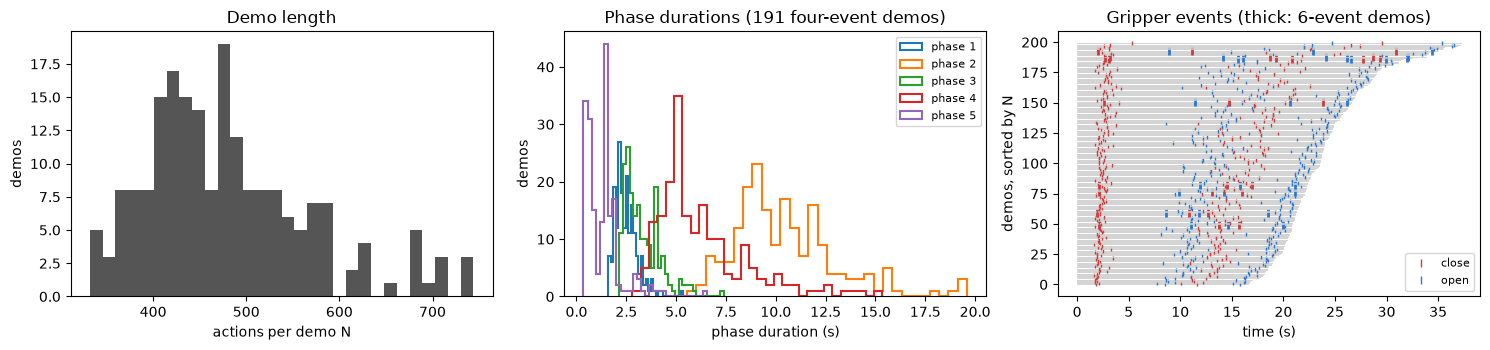

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(N, bins=30, color=COLORS["bar"])
axes[0].set(xlabel="actions per demo N", ylabel="demos", title="Demo length")
for i in range(main.shape[1]):
    axes[1].hist(CONTROL_DT * main[:, i], bins=30, histtype="step", lw=1.5, label=f"phase {i + 1}")
axes[1].set(xlabel="phase duration (s)", ylabel="demos", title="Phase durations (191 four-event demos)")
axes[1].legend(fontsize=8)
order = sorted(KEYS, key=lambda k: INFO[k]["N"])
for row, k in enumerate(order):
    v = INFO[k]
    axes[2].plot([0, CONTROL_DT * v["N"]], [row, row], color="#cccccc", lw=0.6)
    for t, name in zip(v["events"], v["sequence"]):
        axes[2].plot(CONTROL_DT * t, row, "|", color=COLORS[name], ms=3 if len(v["events"]) == 4 else 6, mew=1 if len(v["events"]) == 4 else 2)
axes[2].plot([], [], "|", color=COLORS["close"], label="close")
axes[2].plot([], [], "|", color=COLORS["open"], label="open")
axes[2].set(xlabel="time (s)", ylabel="demos, sorted by N", title="Gripper events (thick: 6-event demos)")
axes[2].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 0.3 Absolute actions

`scripts/convert_lift_abs.py --task tool_hang` wrote `low_dim_abs.hdf5`, and `scripts/validate_lift_abs.py --task tool_hang` checked it with the H15 limits. The report is in `docs/tool_hang/delta-to-absolute-conversion/report.md`. The cell below prints the goal-check table of the report.

In [6]:
report = (ROOT / "docs/tool_hang/delta-to-absolute-conversion/report.md").read_text()
print(report.split("## Goal checks")[1].split("## Goal ranges")[0].strip())
print(report.split("## Warnings")[1].strip())

| Measure | Largest value | Limit |
| --- | --- | --- |
| Position vs controller-free formula (m) | 9.58e-16 | 1e-09 |
| Rotation vs controller-free formula (rad) | 8.10e-07 | 1e-05 |
| Absolute vs delta controller goal position (m) | 4.61e-16 | 1e-09 |
| Absolute vs delta controller goal rotation (rad) | 2.18e-07 | 1e-05 |
| Goal distance from current position (m) | 0.0866 | 0.0866 |
| Goal rotation from current orientation (rad) | 0.5921 | 0.8660 |

The controller comparison covered 95962 steps in all demonstrations.
- Rotation vectors jump between steps. There are 776 jumps above 1.0 rad in 200 demonstrations, because the rotation angle is near pi (min 1.967, median 2.872, max 3.142 rad). The rotations are valid, but later code must not average or fit these three numbers directly.
- 39.4% of pose values lie outside [-1, 1]. robomimic's docs expect normalized actions, and its `get_dataset_info.py` check can reject this file.


## 0.4 Rotation angles of the commands

The fit applies Log only to relative rotations: between consecutive commands (initialization), between the fit and the command (residual), and between nearby controls. The stop rule is a consecutive command step above π/2. Rotation angles of the absolute commands near π only cause rotation-vector wraps in storage, which are information only.

In [7]:
abs_file = h5py.File(ABSOLUTE, "r")
ABS = abs_file["data"]
angles, steps, step_max = [], [], {}
for k in KEYS:
    r = Rotation.from_rotvec(ABS[k]["actions"][:, 3:6])
    angles.append(r.magnitude())
    s = (r[:-1].inv() * r[1:]).magnitude()
    steps.append(s)
    step_max[k] = s.max()
angles, steps = np.concatenate(angles), np.concatenate(steps)
print(f"command rotation angle (rad): min {angles.min():.3f}, median {np.median(angles):.3f}, max {angles.max():.3f}; within 0.1 rad of pi: {(angles > np.pi - 0.1).mean():.1%}")
print(f"consecutive command step (deg): median {np.degrees(np.median(steps)):.2f}, 99th pct {np.degrees(np.percentile(steps, 99)):.2f}, max {np.degrees(steps.max()):.2f}")
print("largest steps:", [(k, round(float(np.degrees(v)), 2)) for k, v in sorted(step_max.items(), key=lambda x: -x[1])[:5]])
record("0.4 largest consecutive command step (rad)", steps.max(), np.pi / 2)

command rotation angle (rad): min 1.967, median 2.872, max 3.142; within 0.1 rad of pi: 25.0%
consecutive command step (deg): median 0.48, 99th pct 3.44, max 31.37
largest steps: [('demo_138', 31.37), ('demo_19', 31.35), ('demo_146', 30.88), ('demo_143', 30.19), ('demo_25', 30.19)]
0.4 largest consecutive command step (rad): 0.5474 (limit <= 1.571) pass


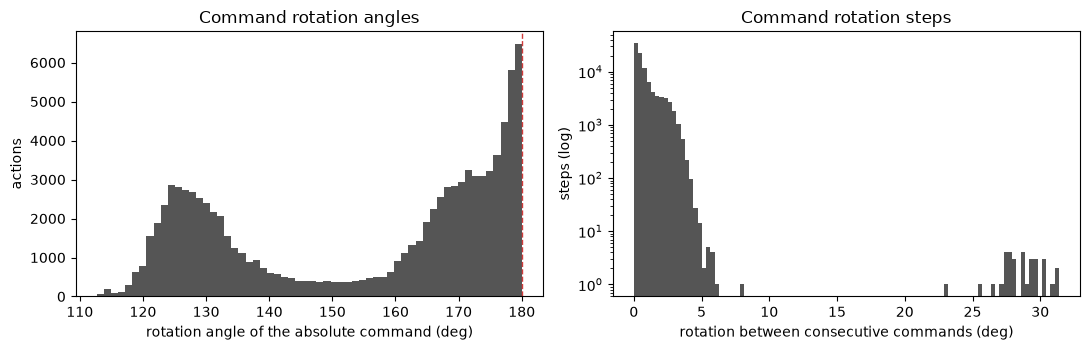

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(np.degrees(angles), bins=60, color=COLORS["bar"])
axes[0].axvline(180, color=COLORS["close"], ls="--", lw=1)
axes[0].set(xlabel="rotation angle of the absolute command (deg)", ylabel="actions", title="Command rotation angles")
axes[1].hist(np.degrees(steps), bins=100, color=COLORS["bar"], log=True)
axes[1].set(xlabel="rotation between consecutive commands (deg)", ylabel="steps (log)", title="Command rotation steps")
plt.tight_layout()
plt.show()

In [9]:
for name, (value, limit, ok) in CHECKS.items():
    print(f"{'pass' if ok else 'FAIL'}  {name}: {value:.4g} (limit {limit:.4g})")

pass  0.1 fraction of steps where actions[t] is best: 1 (limit 0.95)
pass  0.4 largest consecutive command step (rad): 0.5474 (limit 1.571)


---
# Part 1. Replay reference (H25.1)

**Scope after H25.0** (plan section 8): 12 demos. Three four-event demos (demo_0, demo_27, demo_93) and the 9 six-event demos.

**Hypothesis H25.1.** Absolute replay succeeds wherever delta replay from the same start succeeds (H17), and the q0-start replay succeeds wherever the absolute replay succeeds (H21). The q0-start replay is the reference for the fits.

Traces are in `docs/tool_hang/diagnostics/traces.hdf5` (`scripts/build_diagnostic_traces.py` and `scripts/add_replay_traces.py`, both with `--task tool_hang`). Success is `env._check_success()` at each state: the frame is assembled and the tool hangs on the hook without gripper contact. The gate uses success at any step, because a robomimic rollout stops at the first success.

| # | Check | Pass if |
| --- | --- | --- |
| 1 | absolute succeeds wherever delta succeeds, per start | all 12 demos |
| 2 | controller goal = command (absolute, absolute stale, q0start) | ≤ 1e-9 m and rad |
| 3 | q0start succeeds wherever `replay_absolute` succeeds | all 12 demos |
| 4 | grip-site distance q0start vs `replay_absolute`, before the first close | median over demos < 0.1 mm for every k ≥ 25; max ≤ 3 mm for k ≥ 10 |
| 5 | reference set = demos where `replay_q0start` succeeds | report only |

In [3]:
from bezier_rfm.eval.lift_diagnostics import command_fidelity, read_trace

DEMOS = ["demo_0", "demo_27", "demo_93", "demo_16", "demo_18", "demo_36", "demo_40", "demo_113", "demo_139", "demo_151", "demo_191", "demo_196"]
REPLAYS = ["replay_delta_stale", "replay_absolute_stale", "replay_delta", "replay_absolute", "replay_q0start"]
TRACES = ROOT / "docs/tool_hang/diagnostics/traces.hdf5"
TR = {}
with h5py.File(TRACES, "r") as f:
    for d in DEMOS:
        TR[d] = {name: read_trace(f[f"{d}/{name}"])[0] for name in ["recorded", *REPLAYS]}

ok_any = {d: {r: bool(TR[d][r]["success"].any()) for r in ["recorded", *REPLAYS]} for d in DEMOS}
ok_final = {d: {r: bool(TR[d][r]["success"][-1]) for r in ["recorded", *REPLAYS]} for d in DEMOS}
first_ok = {d: {r: int(np.argmax(TR[d][r]["success"])) if ok_any[d][r] else None for r in ["recorded", *REPLAYS]} for d in DEMOS}
print(f"{'demo':9s} " + " ".join(f"{r.replace('replay_', ''):>16s}" for r in ["recorded", *REPLAYS]))
for d in DEMOS:
    cells = [f"{('any@' + str(first_ok[d][r])) if ok_any[d][r] else 'fail':>11s}/{'F' if ok_final[d][r] else '-'}".rjust(16) for r in ["recorded", *REPLAYS]]
    print(f"{d:9s} " + " ".join(cells))
print("(any@k: first successful state k; /F: success also at the final state)")

demo              recorded      delta_stale   absolute_stale            delta         absolute          q0start
demo_0           any@677/-           fail/-        any@676/F           fail/-           fail/-           fail/-
demo_27          any@465/-           fail/-           fail/-           fail/-           fail/-           fail/-
demo_93          any@374/-           fail/-           fail/-           fail/-           fail/-           fail/-
demo_16          any@665/-        any@492/F        any@648/F           fail/-        any@651/F        any@646/F
demo_18          any@605/-           fail/-           fail/-           fail/-           fail/-           fail/-
demo_36          any@528/-           fail/-           fail/-           fail/-           fail/-           fail/-
demo_40          any@645/-        any@534/F           fail/-           fail/-           fail/-           fail/-
demo_113         any@436/-           fail/-           fail/-           fail/-           fail/-          

In [4]:
for start, delta, absolute in (("stale", "replay_delta_stale", "replay_absolute_stale"), ("refreshed", "replay_delta", "replay_absolute")):
    broken = [d for d in DEMOS if ok_any[d][delta] and not ok_any[d][absolute]]
    record(f"1 {start}: demos where delta succeeds but absolute fails", len(broken), 0)
    if broken:
        print("   ", broken)
fid = max(command_fidelity(TR[d][r]).max() for d in DEMOS for r in ("replay_absolute_stale", "replay_absolute", "replay_q0start"))
record("2 command fidelity, largest (m or rad)", fid, 1e-9)
broken = [d for d in DEMOS if ok_any[d]["replay_absolute"] and not ok_any[d]["replay_q0start"]]
record("3 demos where absolute succeeds but q0start fails", len(broken), 0)
if broken:
    print("   ", broken)
REFERENCE = [d for d in DEMOS if ok_any[d]["replay_q0start"]]
print(f"5 reference set: {len(REFERENCE)} of {len(DEMOS)} demos; q0start fails in {[d for d in DEMOS if d not in REFERENCE]}")

1 stale: demos where delta succeeds but absolute fails: 1 (limit <= 0) FAIL
    ['demo_40']
1 refreshed: demos where delta succeeds but absolute fails: 1 (limit <= 0) FAIL
    ['demo_151']
2 command fidelity, largest (m or rad): 0 (limit <= 1e-09) pass
3 demos where absolute succeeds but q0start fails: 1 (limit <= 0) FAIL
    ['demo_139']
5 reference set: 2 of 12 demos; q0start fails in ['demo_0', 'demo_27', 'demo_93', 'demo_18', 'demo_36', 'demo_40', 'demo_113', 'demo_139', 'demo_151', 'demo_191']


In [5]:
# Check 4: start transient of the q0-start replay, before the first close of each demo.
first_close = {d: INFO[d]["events"][0] for d in DEMOS}
kmax = max(first_close.values())
gap = np.full((len(DEMOS), kmax + 1), np.nan)
for i, d in enumerate(DEMOS):
    n = first_close[d] + 1
    gap[i, :n] = np.linalg.norm(TR[d]["replay_q0start"]["ach_pos"][:n] - TR[d]["replay_absolute"]["ach_pos"][:n], axis=1)
k = np.arange(kmax + 1)
med = np.nanmedian(gap, axis=0)
record("4a median gap for k >= 25 before the first close (mm)", 1e3 * np.nanmax(med[25:]), 0.1)
record("4b max gap for k >= 10 before the first close (mm)", 1e3 * np.nanmax(gap[:, 10:]), 3.0)
print(f"first close index: min {min(first_close.values())}, max {kmax}")

4a median gap for k >= 25 before the first close (mm): 0.1095 (limit <= 0.1) FAIL
4b max gap for k >= 10 before the first close (mm): 2.26 (limit <= 3) pass
first close index: min 39, max 69


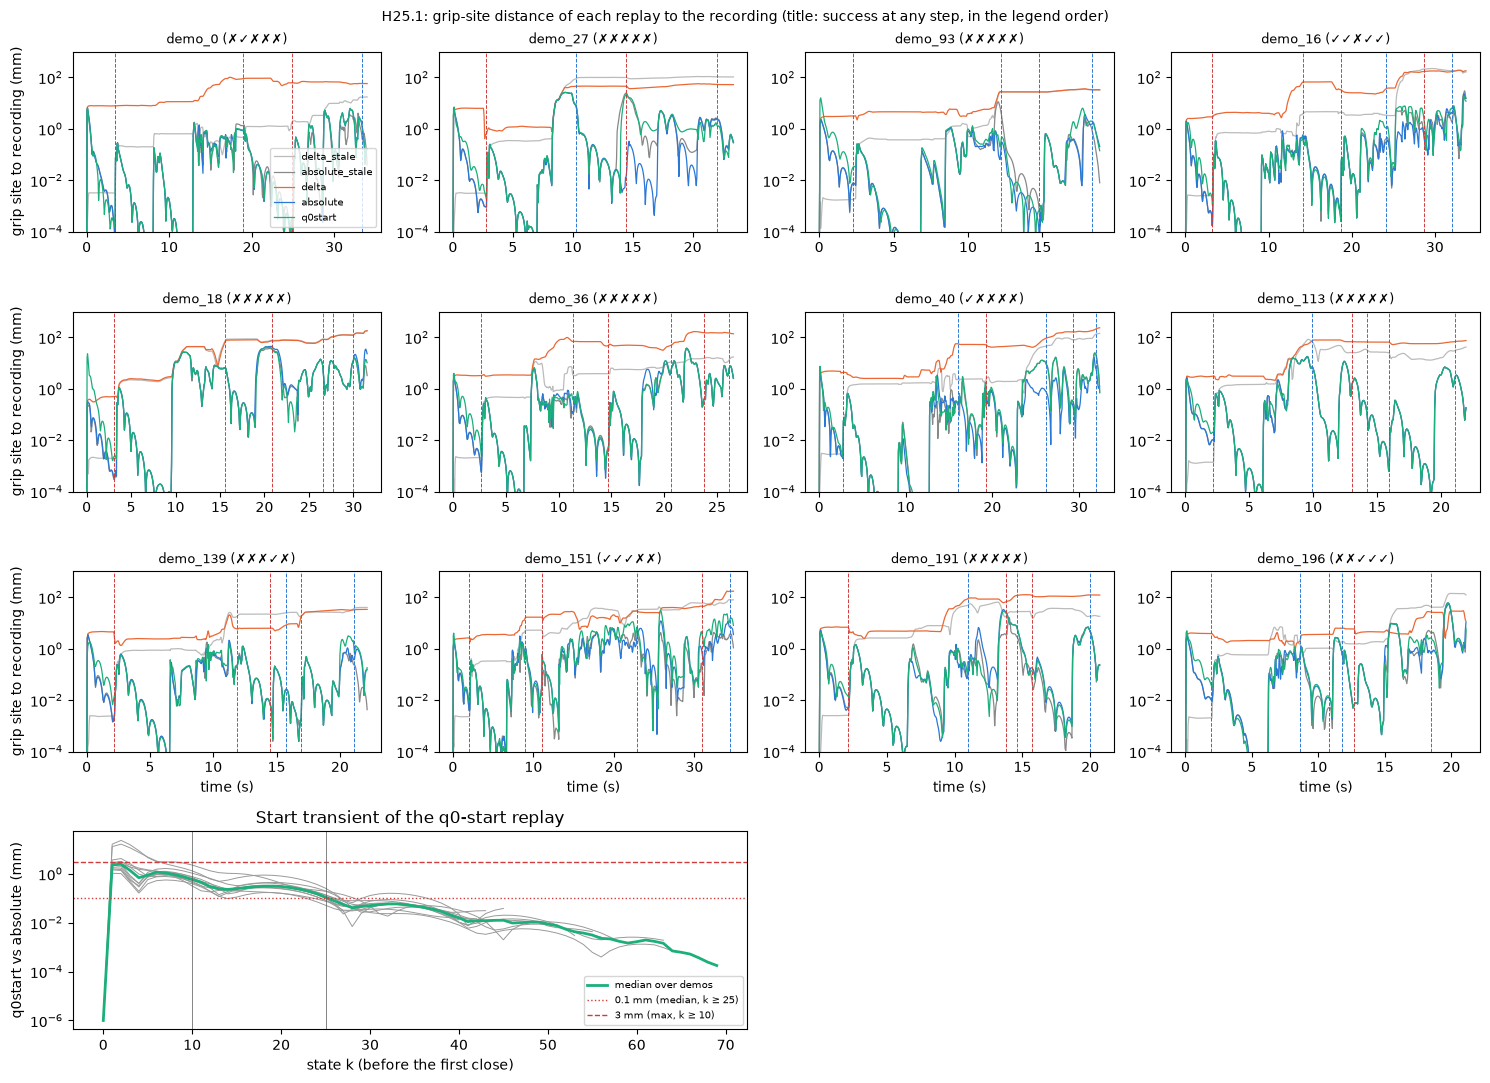

In [6]:
fig = plt.figure(figsize=(15, 11))
grid = fig.add_gridspec(4, 4, height_ratios=[1, 1, 1, 1.1])
colors = {"replay_delta_stale": "#bbbbbb", "replay_absolute_stale": "#888888", "replay_delta": "#eb6834", "replay_absolute": "#2a78d6", "replay_q0start": "#1baf7a"}
for i, d in enumerate(DEMOS):
    ax = fig.add_subplot(grid[i // 4, i % 4])
    rec = TR[d]["recorded"]
    valid = rec["valid"]
    t = CONTROL_DT * np.arange(len(valid))
    for r in REPLAYS:
        dist = np.linalg.norm(TR[d][r]["ach_pos"] - rec["ach_pos"], axis=1)
        ax.semilogy(t[valid], 1e3 * dist[valid] + 1e-6, color=colors[r], lw=0.9, label=r.replace("replay_", ""))
    for e, name in zip(INFO[d]["events"], INFO[d]["sequence"]):
        ax.axvline(CONTROL_DT * e, color=COLORS[name], lw=0.7, ls="--")
    status = "".join("✓" if ok_any[d][r] else "✗" for r in REPLAYS)
    ax.set_title(f"{d} ({status})", fontsize=9)
    ax.set_ylim(1e-4, 1e3)
    if i % 4 == 0:
        ax.set_ylabel("grip site to recording (mm)")
    if i >= 8:
        ax.set_xlabel("time (s)")
fig.axes[0].legend(fontsize=7, loc="lower right")
ax = fig.add_subplot(grid[3, :2])
for i, d in enumerate(DEMOS):
    ax.semilogy(k, 1e3 * gap[i] + 1e-6, color="#999999", lw=0.7)
ax.semilogy(k, 1e3 * med + 1e-6, color="#1baf7a", lw=2, label="median over demos")
ax.axhline(0.1, color="#d03b3b", ls=":", lw=1, label="0.1 mm (median, k ≥ 25)")
ax.axhline(3.0, color="#d03b3b", ls="--", lw=1, label="3 mm (max, k ≥ 10)")
ax.axvline(10, color="#555555", lw=0.5)
ax.axvline(25, color="#555555", lw=0.5)
ax.set(xlabel="state k (before the first close)", ylabel="q0start vs absolute (mm)", title="Start transient of the q0-start replay")
ax.legend(fontsize=7)
fig.suptitle("H25.1: grip-site distance of each replay to the recording (title: success at any step, in the legend order)", fontsize=10)
plt.tight_layout()
plt.show()

**Result of Part 1.** Open-loop replay does not reproduce Tool Hang success: the q0-start replay succeeds in only 2 of the 12 demos, although it stays within about 1–10 mm of the recording. Checks 1 and 3 fail by one demo each, and check 4a fails marginally. Success parity against this reference cannot separate curve error from replay drift, so the demos are screened first (section 1.1).

## 1.1 Screening of all 200 demos

`scripts/screen_replay.py` replays `low_dim_abs_q0start.hdf5` for every demo: one nominal run and 5 runs with Gaussian command noise after action 0 (σ = 0.2 mm per position axis, 0.2 mrad per rotation axis), each followed by up to 60 hold steps that repeat the last command. A demo is **robust** if it succeeds (at any step, holds included) in all 6 runs. The fits use only robust demos.

In [3]:
SCREEN = json.loads((ROOT / "docs/tool_hang/screening/screen_q0start.json").read_text())
print("settings:", {k: SCREEN["settings"][k] for k in ("seeds", "pos_sigma", "rot_sigma", "hold")})
runs = SCREEN["runs"]
by_demo = {}
for r in runs:
    by_demo.setdefault(r["demo"], []).append(r)
wins = {d: sum(r["success_with_hold"] for r in rs) for d, rs in by_demo.items()}
nominal = {d: rs[0] for d, rs in by_demo.items()}
groups = {"4 events": [d for d in KEYS if len(INFO[d]["events"]) == 4], "6 events": [d for d in KEYS if len(INFO[d]["events"]) == 6]}
for g, ks in groups.items():
    print(f"{g} ({len(ks)} demos): nominal success in actions {sum(nominal[d]['success_in_actions'] for d in ks)}, "
          f"nominal with hold {sum(nominal[d]['success_with_hold'] for d in ks)}, robust (6 of 6) {sum(wins[d] == 6 for d in ks)}")
noisy = [r for r in runs if r["seed"] > 0]
print(f"noisy runs: success with hold {sum(r['success_with_hold'] for r in noisy)} of {len(noisy)}")
fails = [r for r in runs if not r["success_with_hold"]]
print(f"failed runs: frame not assembled {sum(not r['frame_assembled'] for r in fails)}, tool not on frame {sum(not r['tool_on_frame'] for r in fails)} of {len(fails)}")
ROBUST = [d for d in KEYS if wins[d] == 6]
print("robust demos:", [(d, INFO[d]["N"], len(INFO[d]["events"])) for d in ROBUST])

settings: {'seeds': 5, 'pos_sigma': 0.0002, 'rot_sigma': 0.0002, 'hold': 60}
4 events (191 demos): nominal success in actions 66, nominal with hold 80, robust (6 of 6) 18
6 events (9 demos): nominal success in actions 2, nominal with hold 2, robust (6 of 6) 1
noisy runs: success with hold 425 of 1000
failed runs: frame not assembled 330, tool not on frame 693 of 693
robust demos: [('demo_16', 676, 6), ('demo_39', 485, 4), ('demo_64', 508, 4), ('demo_66', 461, 4), ('demo_70', 421, 4), ('demo_82', 422, 4), ('demo_90', 410, 4), ('demo_102', 590, 4), ('demo_111', 405, 4), ('demo_118', 404, 4), ('demo_137', 406, 4), ('demo_155', 472, 4), ('demo_162', 487, 4), ('demo_164', 533, 4), ('demo_169', 353, 4), ('demo_174', 452, 4), ('demo_176', 395, 4), ('demo_183', 447, 4), ('demo_189', 519, 4)]


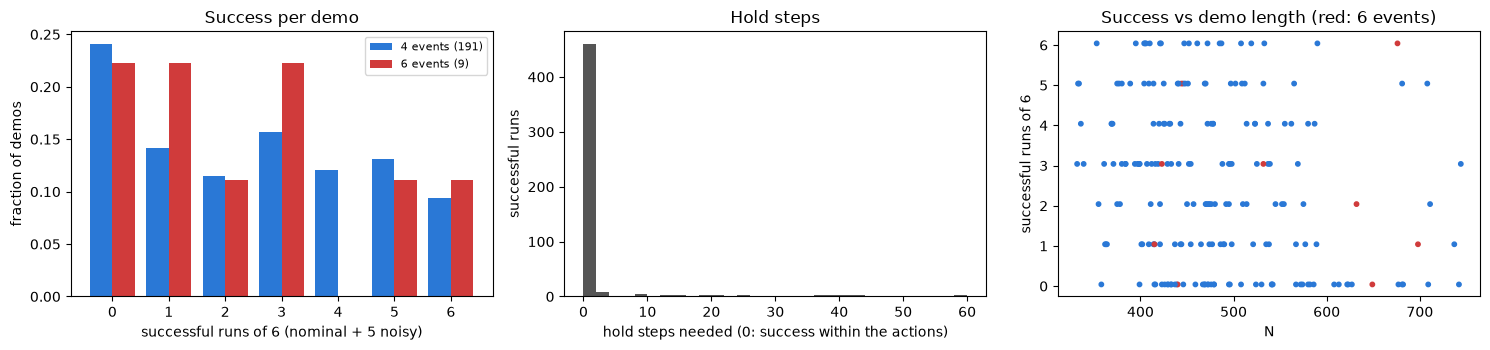

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for g, color in zip(groups, ("#2a78d6", "#d03b3b")):
    counts = np.bincount([wins[d] for d in groups[g]], minlength=7)
    axes[0].bar(np.arange(7) + (-0.2 if g == "4 events" else 0.2), counts / len(groups[g]), width=0.4, color=color, label=f"{g} ({len(groups[g])})")
axes[0].set(xlabel="successful runs of 6 (nominal + 5 noisy)", ylabel="fraction of demos", title="Success per demo")
axes[0].legend(fontsize=8)
hold = [r["hold_steps_needed"] for r in runs if r["success_with_hold"]]
axes[1].hist(hold, bins=np.arange(0, 62, 2), color=COLORS["bar"])
axes[1].set(xlabel="hold steps needed (0: success within the actions)", ylabel="successful runs", title="Hold steps")
n_by = np.array([INFO[d]["N"] for d in KEYS])
axes[2].scatter(n_by, [wins[d] + np.random.default_rng(0).uniform(-0.15, 0.15) for d in KEYS], s=10,
                c=["#d03b3b" if len(INFO[d]["events"]) == 6 else "#2a78d6" for d in KEYS])
axes[2].set(xlabel="N", ylabel="successful runs of 6", title="Success vs demo length (red: 6 events)")
plt.tight_layout()
plt.show()

**Result of section 1.1.** 19 of 200 demos are robust (6 of 6 runs succeed): demo_16 (6 events) and 18 four-event demos. The fits use these 19 demos (plan section 8.1).

---
# Part 2. Decoder with n phases (H25.2)

**Hypothesis H25.2.** The decoder and the fit are correct for any number of phases, and with two phases they reproduce the Lift H24 fits.

The API now takes a list of phase durations and a tuple of segment counts: `knots(durations, ks)`, `decode(c, durations, ks, t)`, `velocity(...)`, `fit(c0, durations, ks, ...)`, `initialize(p, r, events, ks)`, `position_lstsq(...)`. (Since H25.6.1 these functions take one duration per segment, `h`; `phase_h(durations, ks)` gives the equal-per-phase h. The cells below use the new API.) The uniform variant U is the case with one phase. At the knot between phases i and i+1, the duration ratio is ρ = h_i / h_{i+1}; inside a phase ρ = 1.

All synthetic checks use one curve with 4 phases, `ks = (3, 2, 4, 1)` and durations (1.35, 0.30, 2.0, 0.4) s. So h = (0.45, 0.15, 0.5, 0.4) s and ρ = 3, 0.3, 1.25 at the three event knots. (Check 1 of H22, `Exp`/`Log`, is not repeated: `so3.py` did not change.)

| # | Check | Pass if |
| --- | --- | --- |
| 2 | `decode` returns q_k at every knot time; event knot times equal the cumulative sums exactly | ≤ 1e-12; exact |
| 3a | one-sided velocities in seconds agree at every interior knot | ≤ 1e-9 |
| 3b | negative control ρ = 1: jump at the 3 event knots only | > 0.1 at events, ≤ 1e-9 elsewhere |
| 3c | central FD (ε = 1e-8 s) vs one-sided velocity | ≤ 1e-6 |
| 4 | segment end velocities equal ±(3/h) Log | ≤ 1e-10 |
| 5 | residual Jacobian vs central FD | relative ≤ 1e-6 |
| 6 | recovery of a known curve from a perturbed start; q_0 and q_K fixed | RMS ≤ 1e-9; exactly 0 |
| 7 | Lift regression: demo_0–4 with (5, 2) vs stored `bezier_k5_2.hdf5` | ≤ 1e-10 m and rad; gripper equal |
| 8 | U: one phase gives equal h, uniform τ, ρ = 1 | exact |

In [4]:
from bezier_rfm.fitting import so3
from bezier_rfm.fitting.bezier import Controls, decode, knot_times, phase_h, segment_controls, segment_point, velocity
from bezier_rfm.fitting.fit import fit, jacobian, residuals, split_free

rng = np.random.default_rng(0)
KS = (3, 2, 4, 1)
DUR = np.array([1.35, 0.30, 2.0, 0.4])
K = sum(KS)
EVENT_KNOTS = np.cumsum(KS)[:-1]

q_pos = np.linspace([0.0, 0.0, 1.0], [-0.1, 0.05, 0.85], K + 1) + 0.02 * rng.normal(size=(K + 1, 3))
q_rot = Rotation.from_rotvec(0.3 * rng.normal(size=(K + 1, 3))).as_matrix()
h_pos = q_pos + 0.03 * rng.normal(size=(K + 1, 3))
h_rot = q_rot @ Rotation.from_rotvec(0.15 * rng.normal(size=(K + 1, 3))).as_matrix()
TRUE = Controls(q_pos, q_rot, h_pos, h_rot)

H = np.asarray(phase_h(DUR, KS))
TAU = np.asarray(knot_times(H))
print("segment durations h (s):", H)
print("knot times tau (s):     ", TAU)
print("event knots:", EVENT_KNOTS, "| rho there:", H[EVENT_KNOTS - 1] / H[EVENT_KNOTS])

segment durations h (s): [0.45 0.45 0.45 0.15 0.15 0.5  0.5  0.5  0.5  0.4 ]
knot times tau (s):      [0.   0.45 0.9  1.35 1.5  1.65 2.15 2.65 3.15 3.65 4.05]
event knots: [3 5 9] | rho there: [3.   0.3  1.25]


In [5]:
p_k, r_k = decode(TRUE, H, jnp.asarray(TAU))
record("2a |decode(tau_k) - q_k|", max(np.abs(np.asarray(p_k) - q_pos).max(), np.abs(np.asarray(r_k) - q_rot).max()), 1e-12)
starts = np.concatenate([[0.0], np.cumsum(DUR)])
# Since H25.6.1, tau is the cumulative sum of h, so the event knot times agree to round-off, not exactly.
record("2b |tau at event knots and ends - cumulative sums|", np.abs(TAU[np.r_[0, EVENT_KNOTS, K]] - starts).max(), 1e-12)

2a |decode(tau_k) - q_k|: 1.665e-16 (limit <= 1e-12) pass
2b |tau at event knots and ends - cumulative sums|: 8.882e-16 (limit <= 1e-12) pass


In [6]:
P_POS, P_ROT = segment_controls(TRUE, jnp.asarray(H))
NAIVE_POS, NAIVE_ROT = segment_controls(TRUE, jnp.ones(K))  # rho = 1 at every knot


def seg_velocity(pos, rot, k, u):
    """Return [linear, angular] velocity in seconds of segment k at local parameter u.

    Args:
        pos (jnp.ndarray): Control positions, shape (K, 4, 3).
        rot (jnp.ndarray): Control rotations, shape (K, 4, 3, 3).
        k (int): Segment index.
        u (float): Local parameter.

    Returns:
        np.ndarray: Velocity, shape (6,).
    """
    f = lambda x: segment_point(pos[k], rot[k], x)
    (_, r), (dp, dr) = f(u), jax.jacfwd(f)(u)
    return np.r_[dp, so3.vee(r.T @ dr)] / H[k]


EPS = 1e-8
c1, fd, naive_event, naive_other = [], [], [], []
print("knot  tau (s)  |left - right|  |FD - left|  naive |left - right|")
for k in range(1, K):
    left, right = seg_velocity(P_POS, P_ROT, k - 1, 1.0), seg_velocity(P_POS, P_ROT, k, 0.0)
    (pa, pb), (ra, rb) = (np.asarray(a) for a in decode(TRUE, H, jnp.array([TAU[k] - EPS, TAU[k] + EPS])))
    diff = np.r_[(pb - pa) / (2 * EPS), so3.log(ra.T @ rb) / (2 * EPS)]
    c1.append(np.abs(left - right).max())
    fd.append(np.abs(diff - left).max())
    jump = np.abs(seg_velocity(NAIVE_POS, NAIVE_ROT, k - 1, 1.0) - seg_velocity(NAIVE_POS, NAIVE_ROT, k, 0.0)).max()
    (naive_event if k in EVENT_KNOTS else naive_other).append(jump)
    print(f"{k:4d}  {TAU[k]:6.2f}   {c1[-1]:.1e}       {fd[-1]:.1e}      {jump:.1e}{'   <- event knot' if k in EVENT_KNOTS else ''}")
record("3a |left - right velocity| at interior knots", max(c1), 1e-9)
record("3b naive jump at event knots, smallest", min(naive_event), 0.1, larger_passes=True)
record("3b naive jump at other knots, largest", max(naive_other), 1e-9)
record("3c |central FD - one-sided velocity|, eps = 1e-8", max(fd), 1e-6)

knot  tau (s)  |left - right|  |FD - left|  naive |left - right|


   1    0.45   4.4e-16       5.4e-08      4.4e-16


   2    0.90   2.2e-15       1.8e-07      2.2e-15


   3    1.35   1.8e-15       3.7e-07      4.5e+00   <- event knot


   4    1.50   1.2e-15       2.6e-07      1.2e-15


   5    1.65   2.1e-15       3.5e-07      3.0e+00   <- event knot


   6    2.15   1.2e-15       1.0e-07      1.2e-15


   7    2.65   7.8e-16       6.5e-08      7.8e-16


   8    3.15   1.1e-15       9.2e-08      1.1e-15


   9    3.65   8.9e-16       1.1e-07      3.2e-01   <- event knot
3a |left - right velocity| at interior knots: 2.22e-15 (limit <= 1e-09) pass
3b naive jump at event knots, smallest: 0.3201 (limit >= 0.1) pass
3b naive jump at other knots, largest: 2.22e-15 (limit <= 1e-09) pass
3c |central FD - one-sided velocity|, eps = 1e-8: 3.71e-07 (limit <= 1e-06) pass


In [7]:
def log_pose(pos_a, rot_a, pos_b, rot_b):
    """Return log_a(b) = [p_b - p_a, Log(R_a^T R_b)].

    Args:
        pos_a (jnp.ndarray): Position of a, shape (3,).
        rot_a (jnp.ndarray): Rotation of a, shape (3, 3).
        pos_b (jnp.ndarray): Position of b, shape (3,).
        rot_b (jnp.ndarray): Rotation of b, shape (3, 3).

    Returns:
        np.ndarray: Tangent vector, shape (6,).
    """
    return np.r_[pos_b - pos_a, so3.log(rot_a.T @ rot_b)]


err = 0.0
for k in range(K):
    start = 3 / H[k] * log_pose(P_POS[k, 0], P_ROT[k, 0], P_POS[k, 1], P_ROT[k, 1])
    end = -3 / H[k] * log_pose(P_POS[k, 3], P_ROT[k, 3], P_POS[k, 2], P_ROT[k, 2])
    err = max(err, np.abs(seg_velocity(P_POS, P_ROT, k, 0.0) - start).max(), np.abs(seg_velocity(P_POS, P_ROT, k, 1.0) - end).max())
record("4 |autodiff - analytic end velocity|", err, 1e-10)

4 |autodiff - analytic end velocity|: 2.887e-15 (limit <= 1e-10) pass


In [8]:
NS = int(round(DUR.sum() / CONTROL_DT)) + 1
TS = CONTROL_DT * np.arange(NS)
P_T, R_T = (np.asarray(a) for a in decode(TRUE, H, jnp.asarray(TS)))
ENDS = (np.stack([q_pos[0], q_pos[-1]]), np.stack([q_rot[0], q_rot[-1]]))
DATA = (*ENDS, H, TS[1:-1], P_T[1:-1], R_T[1:-1], 1 / np.sqrt(NS))


def perturb_controls(c, pos, ang):
    """Move the free controls by random offsets; q_0 and q_K stay.

    Args:
        c (Controls): Controls.
        pos (float): Position offset scale, m.
        ang (float): Rotation offset scale, rad.

    Returns:
        Controls: Perturbed controls.
    """
    n = len(c.q_pos)
    dq, dh = pos * rng.normal(size=(n, 3)), pos * rng.normal(size=(n, 3))
    rq, rh = (Rotation.from_rotvec(ang * rng.normal(size=(n, 3))).as_matrix() for _ in range(2))
    dq[[0, -1]], rq[[0, -1]] = 0.0, np.eye(3)
    return Controls(c.q_pos + dq, c.q_rot @ rq, c.h_pos + dh, c.h_rot @ rh)


C0 = perturb_controls(TRUE, 0.01, 0.05)


def jacobian_error(c, x):
    """Return the largest relative error of J d vs a central finite difference over 10 directions.

    Args:
        c (Controls): Chart anchors.
        x (np.ndarray): Chart coordinates, shape (12K,).

    Returns:
        float: Largest relative error.
    """
    anchors = split_free(c)
    j = np.asarray(jacobian(x, *anchors, *DATA))
    res = lambda y: np.asarray(residuals(y, *anchors, *DATA))
    worst = 0.0
    for _ in range(10):
        d = rng.normal(size=x.size)
        d /= np.linalg.norm(d)
        fdj = (res(x + 1e-6 * d) - res(x - 1e-6 * d)) / 2e-6
        worst = max(worst, np.linalg.norm(fdj - j @ d) / np.linalg.norm(j @ d))
    return worst


zero = np.zeros(12 * K)
print("residual norm at the true controls:", np.linalg.norm(np.asarray(residuals(zero, *split_free(TRUE), *DATA))))
errors = {"coincident": jacobian_error(TRUE, zero), "perturbed": jacobian_error(C0, zero), "perturbed, off-centre": jacobian_error(C0, 0.01 * rng.normal(size=12 * K))}
for name, value in errors.items():
    print(f"  {name}: {value:.1e}")
record("5 relative |J d - FD|", max(errors.values()), 1e-6)

residual norm at the true controls: 8.458773221604805e-17


  coincident: 4.0e-10
  perturbed: 3.5e-10
  perturbed, off-centre: 3.3e-10
5 relative |J d - FD|: 3.984e-10 (limit <= 1e-06) pass


In [9]:
def rms(c):
    """Return the RMS position (m) and rotation (rad) residual of controls over all samples.

    Args:
        c (Controls): Controls.

    Returns:
        tuple: RMS position and rotation residual.
    """
    p, r = (np.asarray(a) for a in decode(c, H, jnp.asarray(TS)))
    rot = np.asarray(jax.vmap(so3.log)(np.swapaxes(r, 1, 2) @ R_T))
    return np.sqrt(np.mean(np.sum((p - P_T) ** 2, axis=1))), np.sqrt(np.mean(np.sum(rot**2, axis=1)))


print(f"start: RMS {rms(C0)[0]:.1e} m, {rms(C0)[1]:.1e} rad")
for name, trf in (("plan settings", None), ("tight tolerances", {"gtol": 1e-15, "ftol": 1e-15, "xtol": 1e-15})):
    fitted, diag = fit(C0, H, TS[1:-1], P_T[1:-1], R_T[1:-1], NS, trf=trf)
    e_pos, e_rot = rms(fitted)
    nfev = sum(h["nfev"] for h in diag["history"][1:])
    print(f"{name}: RMS {e_pos:.1e} m, {e_rot:.1e} rad; status {diag['status']}, charts {diag['charts']}, active bounds {diag['active']}, evaluations {nfev}")
record("6a RMS residual, tight tolerances", max(e_pos, e_rot), 1e-9)
ends_moved = max(np.abs(fitted.q_pos[[0, -1]] - q_pos[[0, -1]]).max(), np.abs(fitted.q_rot[[0, -1]] - q_rot[[0, -1]]).max())
record("6b |q_0, q_K fitted - true|", ends_moved, 0.0)

start: RMS 1.8e-02 m, 1.0e-01 rad


plan settings: RMS 7.1e-17 m, 2.4e-12 rad; status 1, charts 1, active bounds 0, evaluations 6


tight tolerances: RMS 9.5e-17 m, 1.1e-16 rad; status 1, charts 1, active bounds 0, evaluations 7
6a RMS residual, tight tolerances: 1.119e-16 (limit <= 1e-09) pass
6b |q_0, q_K fitted - true|: 0 (limit <= 0) pass


In [2]:
# Check 7: the generalized code with two phases against the stored Lift H24 fits (K1, K2) = (5, 2).
import sys

sys.path.insert(0, str(ROOT / "scripts"))
from fit_bezier import fit_demo

LIFT = ROOT / "data/robomimic/datasets/lift/ph"
worst_pos, worst_rot, gripper_equal = 0.0, 0.0, True
with h5py.File(LIFT / "low_dim_abs_q0start.hdf5", "r") as fa, h5py.File(LIFT / "bezier_k5_2.hdf5", "r") as fb:
    for name in [f"demo_{i}" for i in range(5)]:
        decoded = fit_demo(fa[f"data/{name}/actions"][:], ks=(5, 2))[4]
        stored = fb[f"data/{name}/actions"][:]
        dp = np.linalg.norm(decoded[:, :3] - stored[:, :3], axis=1).max()
        dr = (Rotation.from_rotvec(decoded[:, 3:6]).inv() * Rotation.from_rotvec(stored[:, 3:6])).magnitude().max()
        gripper_equal &= np.array_equal(decoded[:, 6], stored[:, 6])
        worst_pos, worst_rot = max(worst_pos, dp), max(worst_rot, dr)
        print(f"{name}: max |pos diff| {dp:.1e} m, max rot diff {dr:.1e} rad")
record("7a Lift regression, position (m)", worst_pos, 1e-10)
record("7b Lift regression, rotation (rad)", worst_rot, 1e-10)
record("7c Lift regression, gripper columns differ", float(not gripper_equal), 0.0)

demo_0: max |pos diff| 0.0e+00 m, max rot diff 0.0e+00 rad


demo_1: max |pos diff| 0.0e+00 m, max rot diff 0.0e+00 rad


demo_2: max |pos diff| 0.0e+00 m, max rot diff 0.0e+00 rad


demo_3: max |pos diff| 0.0e+00 m, max rot diff 0.0e+00 rad


demo_4: max |pos diff| 4.4e-16 m, max rot diff 5.6e-16 rad
7a Lift regression, position (m): 4.443e-16 (limit <= 1e-10) pass
7b Lift regression, rotation (rad): 5.625e-16 (limit <= 1e-10) pass
7c Lift regression, gripper columns differ: 0 (limit <= 0) pass


In [11]:
# Check 8: U is the one-phase case.
h_u = np.asarray(phase_h(np.array([DUR.sum()]), (K,)))
tau_u = np.asarray(knot_times(h_u))
pos_u, _ = segment_controls(TRUE, jnp.asarray(h_u))
pos_naive, _ = segment_controls(TRUE, jnp.ones(K))
record("8a U: spread of h", np.ptp(h_u), 0.0)
# Since H25.6.1, tau is the cumulative sum of h, so it agrees with k h to round-off, not exactly.
record("8b U: |tau - k h|", np.abs(tau_u - np.arange(K + 1) * h_u[0]).max(), 1e-12)
record("8c U: |controls - rho = 1 controls|", np.abs(np.asarray(pos_u) - np.asarray(pos_naive)).max(), 0.0)

8a U: spread of h: 0 (limit <= 0) pass
8b U: |tau - k h|: 8.882e-16 (limit <= 1e-12) pass
8c U: |controls - rho = 1 controls|: 0 (limit <= 0) pass


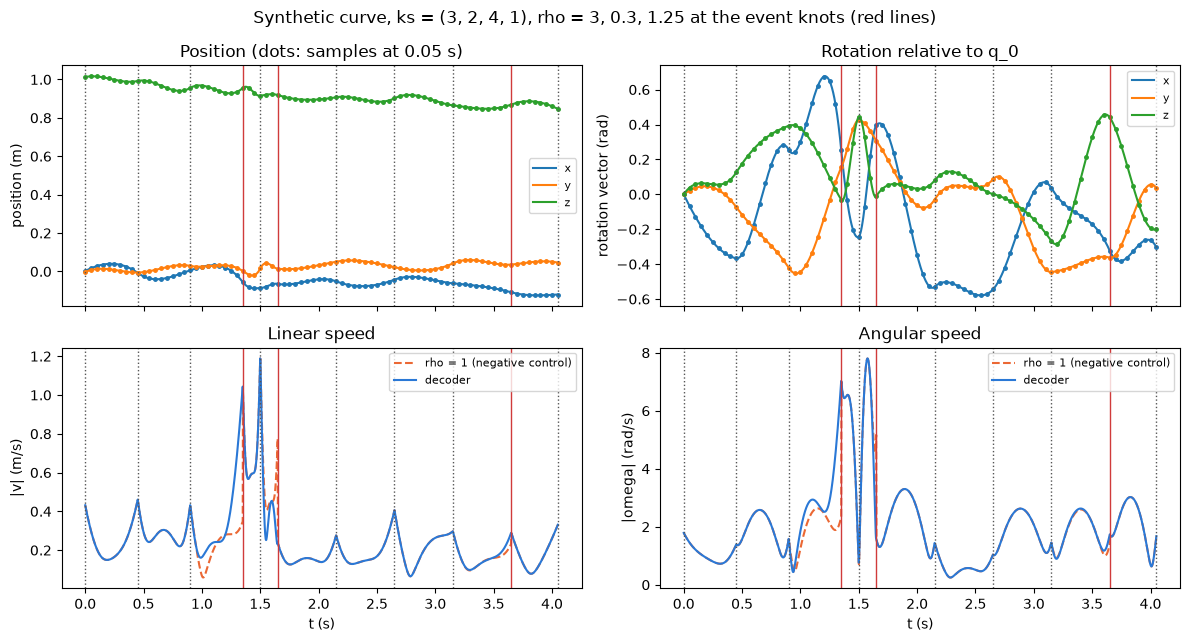

In [12]:
TT = np.linspace(0.0, DUR.sum(), 2000)
p_tt, r_tt = (np.asarray(a) for a in decode(TRUE, H, jnp.asarray(TT)))
v_tt, w_tt = (np.asarray(a) for a in velocity(TRUE, H, jnp.asarray(TT)))
rv_tt = np.asarray(jax.vmap(so3.log)(q_rot[0].T @ r_tt))
rv_t = np.asarray(jax.vmap(so3.log)(q_rot[0].T @ R_T))
seg = np.clip(np.searchsorted(TAU, TT, side="right") - 1, 0, K - 1)
u = (TT - TAU[seg]) / H[seg]
naive_v = np.array([seg_velocity(NAIVE_POS, NAIVE_ROT, k, x) for k, x in zip(seg, u)])

fig, axs = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for i, axis in enumerate("xyz"):
    axs[0, 0].plot(TT, p_tt[:, i], label=axis)
    axs[0, 0].plot(TS, P_T[:, i], "o", ms=2.5, color=axs[0, 0].lines[-1].get_color())
    axs[0, 1].plot(TT, rv_tt[:, i], label=axis)
    axs[0, 1].plot(TS, rv_t[:, i], "o", ms=2.5, color=axs[0, 1].lines[-1].get_color())
axs[1, 0].plot(TT, np.linalg.norm(naive_v[:, :3], axis=1), "--", color="#eb6834", label="rho = 1 (negative control)")
axs[1, 0].plot(TT, np.linalg.norm(v_tt, axis=1), color="#2a78d6", label="decoder")
axs[1, 1].plot(TT, np.linalg.norm(naive_v[:, 3:], axis=1), "--", color="#eb6834", label="rho = 1 (negative control)")
axs[1, 1].plot(TT, np.linalg.norm(w_tt, axis=1), color="#2a78d6", label="decoder")
for ax in axs.flat:
    for k, tk in enumerate(TAU):
        event = k in EVENT_KNOTS
        ax.axvline(tk, color=COLORS["close"] if event else "#555555", ls="-" if event else ":", lw=1)
    ax.legend(fontsize=8)
axs[0, 0].set(ylabel="position (m)", title="Position (dots: samples at 0.05 s)")
axs[0, 1].set(ylabel="rotation vector (rad)", title="Rotation relative to q_0")
axs[1, 0].set(xlabel="t (s)", ylabel="|v| (m/s)", title="Linear speed")
axs[1, 1].set(xlabel="t (s)", ylabel="|omega| (rad/s)", title="Angular speed")
fig.suptitle("Synthetic curve, ks = (3, 2, 4, 1), rho = 3, 0.3, 1.25 at the event knots (red lines)")
fig.tight_layout()
plt.show()

In [13]:
part2 = {k: v for k, v in CHECKS.items() if k[0] in "2345678"}
for name, (value, limit, ok) in part2.items():
    print(f"{'pass' if ok else 'FAIL'}  {name}: {value:.2e} (limit {limit:.0e})")
print(f"\n{sum(ok for *_, ok in part2.values())} of {len(part2)} checks pass")

pass  2a |decode(tau_k) - q_k|: 1.67e-16 (limit 1e-12)
pass  2b |tau at event knots and ends - cumulative sums|: 8.88e-16 (limit 1e-12)
pass  3a |left - right velocity| at interior knots: 2.22e-15 (limit 1e-09)
pass  3b naive jump at event knots, smallest: 3.20e-01 (limit 1e-01)
pass  3b naive jump at other knots, largest: 2.22e-15 (limit 1e-09)
pass  3c |central FD - one-sided velocity|, eps = 1e-8: 3.71e-07 (limit 1e-06)
pass  4 |autodiff - analytic end velocity|: 2.89e-15 (limit 1e-10)
pass  5 relative |J d - FD|: 3.98e-10 (limit 1e-06)
pass  6a RMS residual, tight tolerances: 1.12e-16 (limit 1e-09)
pass  6b |q_0, q_K fitted - true|: 0.00e+00 (limit 0e+00)
pass  7a Lift regression, position (m): 4.44e-16 (limit 1e-10)
pass  7b Lift regression, rotation (rad): 5.63e-16 (limit 1e-10)
pass  7c Lift regression, gripper columns differ: 0.00e+00 (limit 0e+00)
pass  8a U: spread of h: 0.00e+00 (limit 0e+00)
pass  8b U: |tau - k h|: 8.88e-16 (limit 1e-12)
pass  8c U: |controls - rho = 1 con

**Result of H25.2: confirmed.** All 16 checks pass. The velocity in seconds is continuous at every knot, and the ρ = 1 control jumps only at the three event knots (0.32 to 4.5). The generalized code reproduces the stored Lift (5, 2) fits of demo_0 to demo_4 exactly, and the one-phase case gives the uniform knots of U.

---
# Part 3. Fits on demo_16 (H25.3)

**Hypothesis H25.3.** The fit converges on demo_16 (N = 676, 6 events, 7 phases) for both knot rules at ρ = 3 segments/s:

- **E:** one knot at every event; K_i = max(1, round(3 T_i)) per phase.
- **U:** the same total K in equal segments; the gripper events are not knots.

The code is `fit_demo` of `scripts/fit_bezier.py` (`density=3.0`, `variant="event"` or `"uniform"`).

| # | Check | Pass if |
| --- | --- | --- |
| 1 | TRF stops on a tolerance (status 1–4), not on `max_nfev` | E and U |
| 2 | fitted positions vs the closed-form least squares `position_lstsq` | ≤ 1e-9 m |
| 3 | q_0 and q_K equal the commands | exact |
| 4 | E: the decoded gripper (switches at the event knots) equals the stored column; U uses the stored column | exact |
| 5 | residual RMS and max (mm, deg), overall and within ±10 steps of each event | report only; flags 3 mm / 1° |

In [5]:
import time

from bezier_rfm.fitting.fit import position_lstsq

FIT_DEMO = "demo_16"
with h5py.File(DATA / "low_dim_abs_q0start.hdf5", "r") as f:
    A16 = f[f"data/{FIT_DEMO}/actions"][:]
N16 = len(A16)
P16, R16 = A16[:, :3], Rotation.from_rotvec(A16[:, 3:6]).as_matrix()
T16 = CONTROL_DT * np.arange(N16)
EV16 = INFO[FIT_DEMO]["events"]
FITS = {}
for variant in ("event", "uniform"):
    c, h, ks, _, decoded, diag = fit_demo(A16, density=3.0, variant=variant)
    FITS[variant] = {"c": c, "h": h, "ks": ks, "decoded": decoded, "diag": diag}
    nfev = sum(h["nfev"] for h in diag["history"][1:])
    print(f"{variant:7s} ks {ks} (K = {sum(ks)}, J = {2 * sum(ks) + 2}): status {diag['status']}, charts {diag['charts']}, "
          f"active bounds {diag['active']}, evaluations {nfev}, cost {diag['history'][0]['cost']:.3e} -> {diag['cost']:.3e}, {diag['seconds']:.1f} s")

event   ks (9, 33, 14, 16, 14, 10, 5) (K = 101, J = 204): status 1, charts 1, active bounds 0, evaluations 4, cost 9.162e-05 -> 1.756e-05, 13.3 s


uniform ks (101,) (K = 101, J = 204): status 1, charts 1, active bounds 0, evaluations 4, cost 7.371e-05 -> 1.755e-05, 10.6 s


In [6]:
for variant, fr in FITS.items():
    d, c = fr["diag"], fr["c"]
    record(f"1 {variant}: TRF status in 1..4 (1 = pass)", float(1 <= d["status"] <= 4), 1.0, larger_passes=True)
    best = position_lstsq(c, fr["h"], T16[1:-1], P16[1:-1])
    record(f"2 {variant}: |fitted - closed-form positions| (m)", np.abs(split_free(c)[0] - best).max(), 1e-9)
    ends = max(np.abs(c.q_pos[[0, -1]] - P16[[0, -1]]).max(), np.abs(c.q_rot[[0, -1]] - R16[[0, -1]]).max())
    record(f"3 {variant}: |q_0, q_K - commands|", ends, 0.0)
    record(f"4 {variant}: gripper columns differ", float(not np.array_equal(fr["decoded"][:, 6], A16[:, 6])), 0.0)

1 event: TRF status in 1..4 (1 = pass): 1 (limit >= 1) pass


2 event: |fitted - closed-form positions| (m): 3.782e-14 (limit <= 1e-09) pass
3 event: |q_0, q_K - commands|: 0 (limit <= 0) pass
4 event: gripper columns differ: 0 (limit <= 0) pass
1 uniform: TRF status in 1..4 (1 = pass): 1 (limit >= 1) pass


2 uniform: |fitted - closed-form positions| (m): 4.499e-14 (limit <= 1e-09) pass
3 uniform: |q_0, q_K - commands|: 0 (limit <= 0) pass
4 uniform: gripper columns differ: 0 (limit <= 0) pass


In [7]:
def residuals_mm_deg(decoded):
    """Return the per-action position (mm) and rotation (deg) residual of decoded actions vs the commands.

    Args:
        decoded (np.ndarray): Decoded absolute actions, shape (N, 7).

    Returns:
        tuple: Position residual, shape (N,), and rotation residual, shape (N,).
    """
    pos = 1e3 * np.linalg.norm(decoded[:, :3] - P16, axis=1)
    rot = np.degrees((Rotation.from_rotvec(decoded[:, 3:6]).inv() * Rotation.from_matrix(R16)).magnitude())
    return pos, rot


WINDOW = 10
near = np.zeros(N16, bool)
for e in EV16:
    near[max(e - WINDOW, 0): e + WINDOW + 1] = True
RES = {v: residuals_mm_deg(fr["decoded"]) for v, fr in FITS.items()}
stat = lambda x: f"RMS {np.sqrt(np.mean(x**2)):5.2f}  max {x.max():6.2f}"
for v, (pos, rot) in RES.items():
    print(f"{v:7s} all:      pos {stat(pos)} mm (at action {pos.argmax()}) | rot {stat(rot)} deg (at action {rot.argmax()})")
    print(f"{'':7s} ±{WINDOW} events: pos {stat(pos[near])} mm | rot {stat(rot[near])} deg")
    print(f"{'':7s} other:    pos {stat(pos[~near])} mm | rot {stat(rot[~near])} deg")
    print(f"{'':7s} flags: pos > 3 mm at {np.count_nonzero(pos > 3)} actions, rot > 1 deg at {np.count_nonzero(rot > 1)} actions; "
          f"without action 1: max pos {np.delete(pos, 1).max():.2f} mm")
print("\nper event (window ±10): pos RMS mm E / U, rot RMS deg E / U")
for e, name in zip(EV16, INFO[FIT_DEMO]["sequence"]):
    w = slice(max(e - WINDOW, 0), e + WINDOW + 1)
    pe, re_ = RES["event"][0][w], RES["event"][1][w]
    pu, ru = RES["uniform"][0][w], RES["uniform"][1][w]
    print(f"  {name:5s} @ {e:3d}: {np.sqrt(np.mean(pe**2)):5.2f} / {np.sqrt(np.mean(pu**2)):5.2f} mm   {np.sqrt(np.mean(re_**2)):5.3f} / {np.sqrt(np.mean(ru**2)):5.3f} deg")

event   all:      pos RMS  5.36  max  31.58 mm (at action 2) | rot RMS  0.14  max   1.25 deg (at action 1)
        ±10 events: pos RMS  3.91  max  10.71 mm | rot RMS  0.14  max   0.40 deg
        other:    pos RMS  5.64  max  31.58 mm | rot RMS  0.15  max   1.25 deg
        flags: pos > 3 mm at 349 actions, rot > 1 deg at 1 actions; without action 1: max pos 31.58 mm
uniform all:      pos RMS  5.34  max  32.07 mm (at action 2) | rot RMS  0.15  max   1.20 deg (at action 1)
        ±10 events: pos RMS  3.94  max   9.75 mm | rot RMS  0.14  max   0.42 deg
        other:    pos RMS  5.61  max  32.07 mm | rot RMS  0.15  max   1.20 deg
        flags: pos > 3 mm at 330 actions, rot > 1 deg at 1 actions; without action 1: max pos 32.07 mm

per event (window ±10): pos RMS mm E / U, rot RMS deg E / U
  close @  63:  4.35 /  4.14 mm   0.150 / 0.143 deg
  open  @ 282:  4.39 /  4.38 mm   0.120 / 0.122 deg
  close @ 374:  3.42 /  3.42 mm   0.113 / 0.113 deg
  open  @ 482:  2.57 /  2.66 mm   0.088 / 0

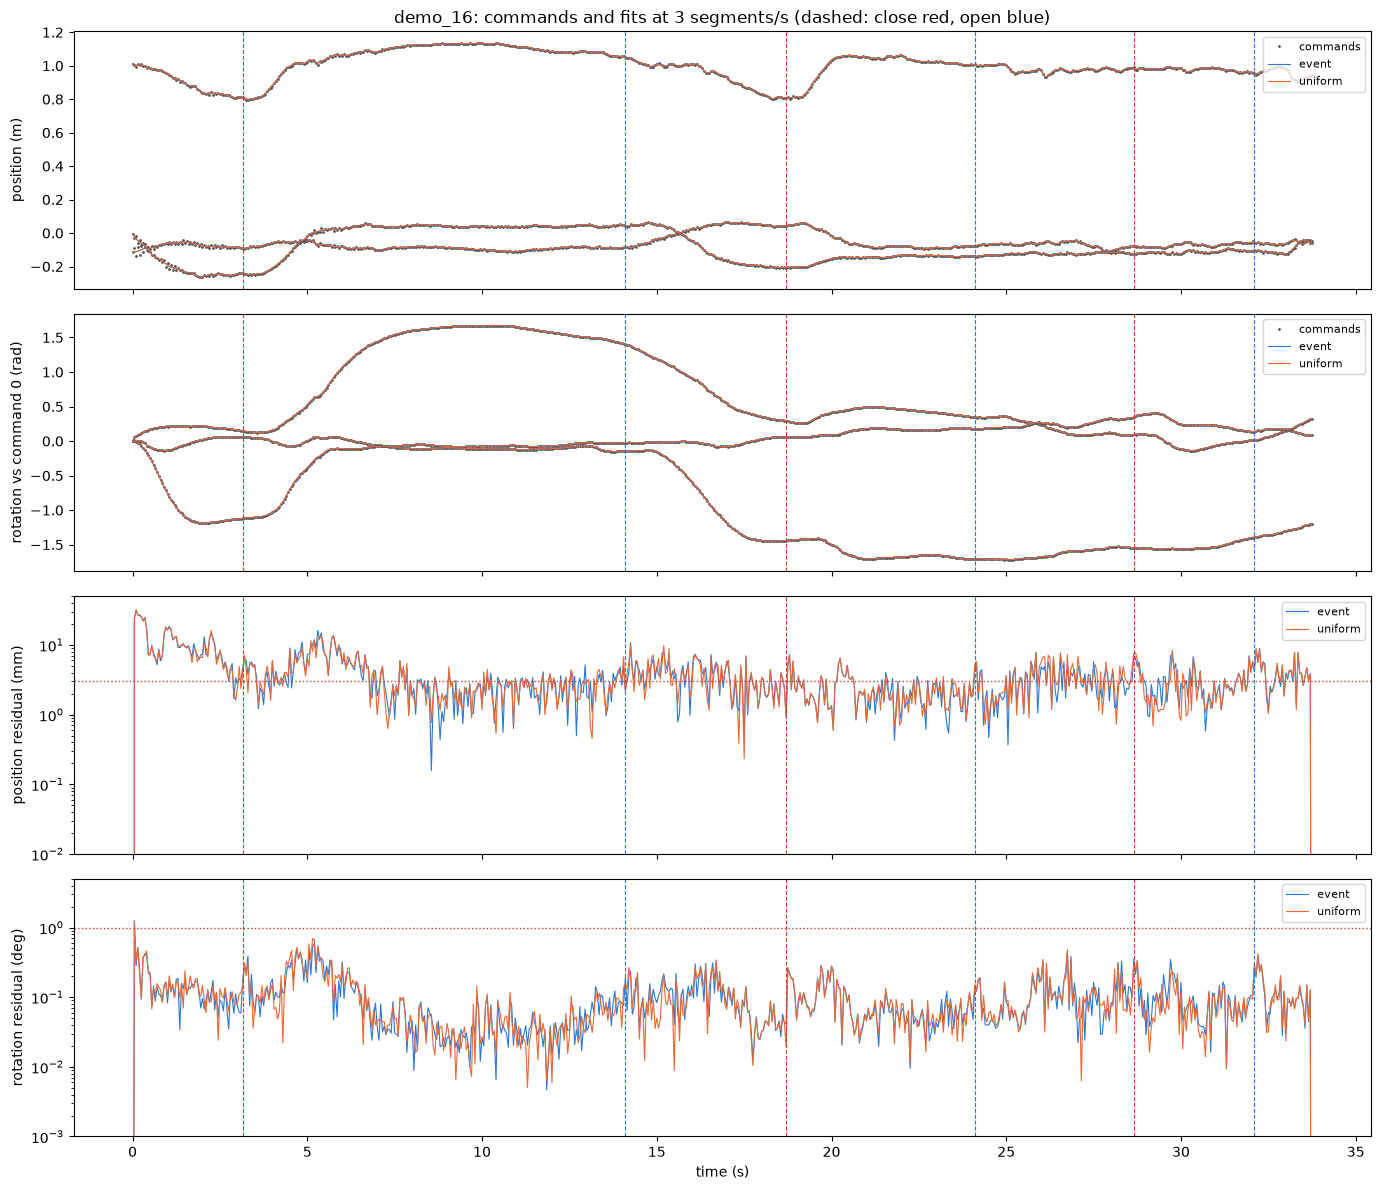

In [8]:
colors_v = {"event": "#2a78d6", "uniform": "#eb6834"}
rv_cmd = Rotation.from_matrix(R16[0].T @ R16).as_rotvec()
fig, axs = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for i, axis in enumerate("xyz"):
    axs[0].plot(T16, P16[:, i], ".", ms=2, color="#555555", label="commands" if i == 0 else None)
    axs[1].plot(T16, rv_cmd[:, i], ".", ms=2, color="#555555", label="commands" if i == 0 else None)
    for v, fr in FITS.items():
        rv = Rotation.from_matrix(R16[0].T @ Rotation.from_rotvec(fr["decoded"][:, 3:6]).as_matrix()).as_rotvec()
        axs[0].plot(T16, fr["decoded"][:, i], color=colors_v[v], lw=0.8, label=v if i == 0 else None)
        axs[1].plot(T16, rv[:, i], color=colors_v[v], lw=0.8, label=v if i == 0 else None)
for v, (pos, rot) in RES.items():
    axs[2].plot(T16, pos, color=colors_v[v], lw=0.8, label=v)
    axs[3].plot(T16, rot, color=colors_v[v], lw=0.8, label=v)
axs[2].axhline(3, color="#d03b3b", ls=":", lw=1)
axs[3].axhline(1, color="#d03b3b", ls=":", lw=1)
for ax in axs:
    for e, name in zip(EV16, INFO[FIT_DEMO]["sequence"]):
        ax.axvline(CONTROL_DT * e, color=COLORS[name], lw=0.8, ls="--")
    ax.legend(fontsize=8, loc="upper right")
axs[0].set(ylabel="position (m)", title=f"{FIT_DEMO}: commands and fits at 3 segments/s (dashed: close red, open blue)")
axs[1].set(ylabel="rotation vs command 0 (rad)")
axs[2].set(ylabel="position residual (mm)", yscale="log", ylim=(1e-2, 50))
axs[3].set(ylabel="rotation residual (deg)", yscale="log", ylim=(1e-3, 5), xlabel="time (s)")
fig.tight_layout()
plt.show()

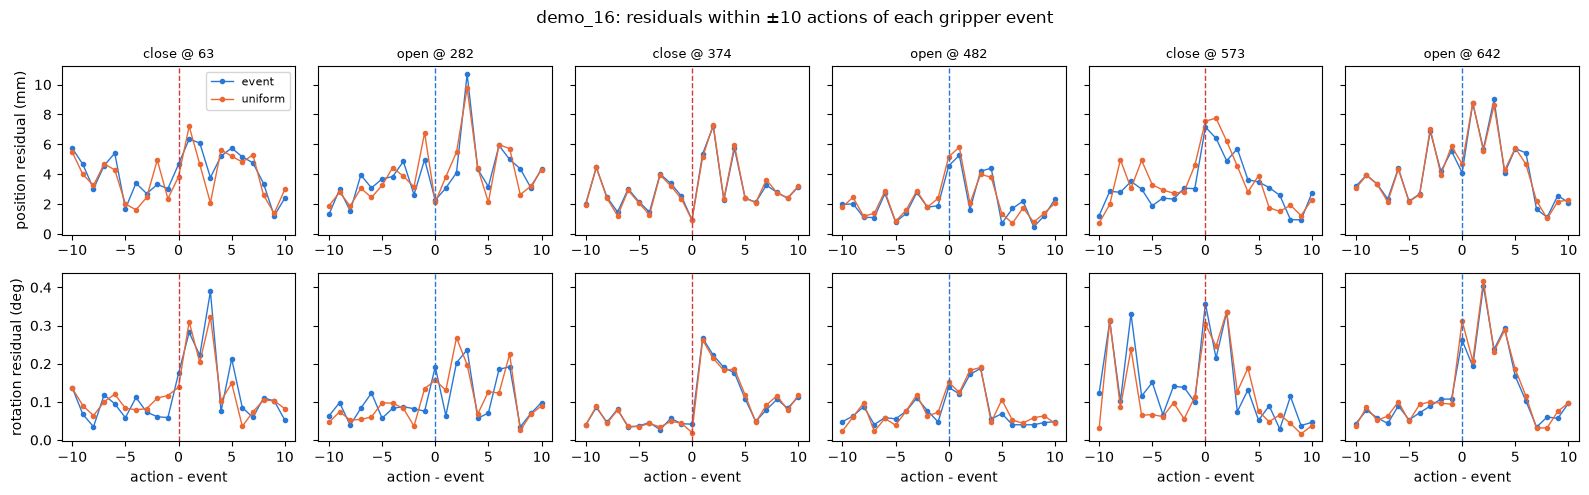

In [9]:
fig, axs = plt.subplots(2, len(EV16), figsize=(16, 5), sharey="row")
offsets = np.arange(-WINDOW, WINDOW + 1)
for j, (e, name) in enumerate(zip(EV16, INFO[FIT_DEMO]["sequence"])):
    idx = np.clip(e + offsets, 0, N16 - 1)
    for v, (pos, rot) in RES.items():
        axs[0, j].plot(offsets, pos[idx], "o-", ms=3, lw=1, color=colors_v[v], label=v)
        axs[1, j].plot(offsets, rot[idx], "o-", ms=3, lw=1, color=colors_v[v], label=v)
    for ax in axs[:, j]:
        ax.axvline(0, color=COLORS[name], lw=1, ls="--")
    axs[0, j].set_title(f"{name} @ {e}", fontsize=9)
    axs[1, j].set_xlabel("action - event")
axs[0, 0].set_ylabel("position residual (mm)")
axs[1, 0].set_ylabel("rotation residual (deg)")
axs[0, 0].legend(fontsize=8)
fig.suptitle(f"{FIT_DEMO}: residuals within ±{WINDOW} actions of each gripper event")
fig.tight_layout()
plt.show()

**Result of H25.3: confirmed.** Both fits converge in one chart with 4 evaluations (status 1, no active bound), the positions equal the closed-form optimum to 4.5e-14 m, q_0 and q_K are exact, and the E gripper rule reproduces the stored column. At 3 segments/s, E and U give almost the same residuals: position RMS 5.4 / 5.3 mm and rotation RMS 0.14 / 0.15 deg, also within ±10 steps of the events. The largest residuals are at actions 1–2 (start jump). Elsewhere the position residual is mostly step-to-step jitter of the commands, which the curve smooths out; about half of the actions are above the 3 mm flag. Whether this smoothing matters is a replay question (H25.4).

---
# Part 4. Fits of the 19 robust demos and replay (H25.4)

**Hypothesis H25.4.** Cubic Bézier fits of the 19 robust demos execute Tool Hang as reliably as the q0-start replay, for event knots (E) and uniform knots (U) at 3 and 1.5 segments/s.

- Fits: `scripts/fit_bezier.py --task tool_hang --variant {event, uniform} --density {3, 1.5}` → `bezier_{variant}_rho{density}.hdf5`.
- Replays: `scripts/screen_replay.py --actions <file> --save-paths`, the screening protocol (nominal + 5 noisy runs at 0.2 mm / 0.2 mrad, 60 hold steps). The reference (q0-start) was replayed again on the 19 demos with the same script.

| Question | Measure | Rule |
| --- | --- | --- |
| 1. Can the curves execute Tool Hang? | demos with 6 of 6, total successes of 114 | pass: all 19 demos at 6 of 6; 4–5 of 6 is borderline |
| 1. flags | max achieved grip-site difference to the reference (nominal runs), gripper open vs closed | report; 3 mm / 1° |
| 2. Do event knots help? | E vs U at equal K, paired per demo: successes, residual RMS, residual RMS within ±10 steps of the events | clear only if the sign test over 19 demos gives p < 0.05 |

In [3]:
from scipy.stats import binomtest

ROBUST19 = ["demo_16", "demo_39", "demo_64", "demo_66", "demo_70", "demo_82", "demo_90", "demo_102", "demo_111", "demo_118",
            "demo_137", "demo_155", "demo_162", "demo_164", "demo_169", "demo_174", "demo_176", "demo_183", "demo_189"]
CANDS = [("event", 3), ("uniform", 3), ("event", 1.5), ("uniform", 1.5)]
SCREEN_DIR = ROOT / "docs/tool_hang/screening"


def load_screen(name):
    """Load one screening result: successes per demo and the nominal grip-site paths.

    Args:
        name (str): File stem in SCREEN_DIR.

    Returns:
        tuple: Successes of 6 per demo (dict), run records (list), and paths (dict of arrays).
    """
    runs = json.loads((SCREEN_DIR / f"{name}.json").read_text())["runs"]
    wins_ = {d: sum(r["success_with_hold"] for r in runs if r["demo"] == d) for d in ROBUST19}
    paths = dict(np.load(SCREEN_DIR / f"{name}.paths.npz"))
    return wins_, runs, paths


REF_WINS, REF_RUNS, REF_PATHS = load_screen("h25_4_reference")
CW, CRUNS, CPATHS, CFITS = {}, {}, {}, {}
with h5py.File(DATA / "low_dim_abs_q0start.hdf5", "r") as f:
    CMD = {d: f[f"data/{d}/actions"][:] for d in ROBUST19}
for v, rho in CANDS:
    CW[v, rho], CRUNS[v, rho], CPATHS[v, rho] = load_screen(f"h25_4_{v}_rho{rho:g}")
    with h5py.File(DATA / f"bezier_{v}_rho{rho:g}.hdf5", "r") as f:
        CFITS[v, rho] = {d: {"actions": f[f"data/{d}/actions"][:], "ks": tuple(f[f"data/{d}/bezier"].attrs["ks"]),
                             "diag": json.loads(f[f"data/{d}/bezier"].attrs["diagnostics"])} for d in ROBUST19}
label = lambda v, rho: f"{'E' if v == 'event' else 'U'} {rho:g}/s"
print(f"{'demo':9s} {'N':>4s} {'K@3':>4s} {'K@1.5':>5s}  ref " + " ".join(f"{label(*c):>8s}" for c in CANDS))
for d in ROBUST19:
    print(f"{d:9s} {len(CMD[d]):4d} {sum(CFITS['event', 3][d]['ks']):4d} {sum(CFITS['event', 1.5][d]['ks']):5d}  {REF_WINS[d]:3d} "
          + " ".join(f"{CW[c][d]:8d}" for c in CANDS))
print(f"\n{'':9s} {'':4s} {'':4s} {'':5s}  {sum(REF_WINS.values()):3d} " + " ".join(f"{sum(CW[c].values()):8d}" for c in CANDS) + "   (total of 114)")

demo         N  K@3 K@1.5  ref    E 3/s    U 3/s  E 1.5/s  U 1.5/s
demo_16    676  101    50    6        4        4        0        0
demo_39    485   74    36    6        5        6        2        6
demo_64    508   75    38    6        6        6        0        0
demo_66    461   69    33    6        2        2        1        2
demo_70    421   63    31    6        5        5        4        3
demo_82    422   63    32    6        1        2        0        0
demo_90    410   60    30    6        5        3        0        2
demo_102   590   89    44    6        6        6        6        6
demo_111   405   61    30    6        6        6        6        5
demo_118   404   61    30    6        5        6        4        0
demo_137   406   61    30    6        4        4        0        0
demo_155   472   69    35    6        4        5        0        1
demo_162   487   72    37    6        5        4        6        5
demo_164   533   81    39    6        6        5        3     

In [4]:
for c in CANDS:
    full = sum(CW[c][d] == 6 for d in ROBUST19)
    fails = {d: CW[c][d] for d in ROBUST19 if CW[c][d] < 6}
    diag = [CFITS[c][d]["diag"] for d in ROBUST19]
    print(f"{label(*c)}: 6 of 6 in {full} of 19 demos, total {sum(CW[c].values())} of 114; "
          f"TRF status {sorted(set(x['status'] for x in diag))}, charts max {max(x['charts'] for x in diag)}, active max {max(x['active'] for x in diag)}, "
          f"fit time median {np.median([x['seconds'] for x in diag]):.0f} s")
    print(f"    below 6 of 6: {fails}")
    record(f"H25.4 {label(*c)}: demos below 6 of 6", len(fails), 0)

E 3/s: 6 of 6 in 4 of 19 demos, total 81 of 114; TRF status [1], charts max 1, active max 0, fit time median 68 s
    below 6 of 6: {'demo_16': 4, 'demo_39': 5, 'demo_66': 2, 'demo_70': 5, 'demo_82': 1, 'demo_90': 5, 'demo_118': 5, 'demo_137': 4, 'demo_155': 4, 'demo_162': 5, 'demo_169': 5, 'demo_174': 5, 'demo_176': 3, 'demo_183': 4, 'demo_189': 0}
H25.4 E 3/s: demos below 6 of 6: 15 (limit <= 0) FAIL
U 3/s: 6 of 6 in 7 of 19 demos, total 87 of 114; TRF status [1], charts max 1, active max 0, fit time median 67 s
    below 6 of 6: {'demo_16': 4, 'demo_66': 2, 'demo_70': 5, 'demo_82': 2, 'demo_90': 3, 'demo_137': 4, 'demo_155': 5, 'demo_162': 4, 'demo_164': 5, 'demo_169': 5, 'demo_183': 5, 'demo_189': 1}
H25.4 U 3/s: demos below 6 of 6: 12 (limit <= 0) FAIL
E 1.5/s: 6 of 6 in 3 of 19 demos, total 38 of 114; TRF status [1], charts max 1, active max 0, fit time median 65 s
    below 6 of 6: {'demo_16': 0, 'demo_39': 2, 'demo_64': 0, 'demo_66': 1, 'demo_70': 4, 'demo_82': 0, 'demo_90': 0,

In [5]:
# Flags: largest achieved grip-site difference to the reference, nominal runs, gripper open (free) vs closed (contact).
FLAG = {}
for c in CANDS:
    rows = []
    for d in ROBUST19:
        a, b = CPATHS[c], REF_PATHS
        dp = 1e3 * np.linalg.norm(a[f"{d}_pos"] - b[f"{d}_pos"], axis=1)
        dr = np.degrees(Rotation.from_matrix(np.swapaxes(a[f"{d}_rot"], 1, 2) @ b[f"{d}_rot"]).magnitude())
        closed = CMD[d][:, 6] > 0
        rows.append((dp[~closed].max(), dr[~closed].max(), dp[closed].max(), dr[closed].max()))
    FLAG[c] = np.array(rows)
    r = FLAG[c]
    print(f"{label(*c)}: free max {r[:, 0].max():6.1f} mm {r[:, 1].max():5.2f} deg (flagged demos {np.sum((r[:, 0] > 3) | (r[:, 1] > 1))}) | "
          f"contact max {r[:, 2].max():6.1f} mm {r[:, 3].max():5.2f} deg (flagged demos {np.sum((r[:, 2] > 3) | (r[:, 3] > 1))}); "
          f"median per demo: free {np.median(r[:, 0]):.1f} mm, contact {np.median(r[:, 2]):.1f} mm")

E 3/s: free max   70.8 mm  3.89 deg (flagged demos 16) | contact max   18.6 mm  0.90 deg (flagged demos 17); median per demo: free 8.6 mm, contact 5.9 mm
U 3/s: free max   56.1 mm  3.16 deg (flagged demos 17) | contact max   22.3 mm  0.72 deg (flagged demos 15); median per demo: free 13.6 mm, contact 4.4 mm
E 1.5/s: free max   70.9 mm  4.05 deg (flagged demos 19) | contact max   47.1 mm  8.52 deg (flagged demos 19); median per demo: free 19.5 mm, contact 12.2 mm
U 1.5/s: free max   88.1 mm  3.43 deg (flagged demos 19) | contact max   28.9 mm  1.05 deg (flagged demos 19); median per demo: free 20.1 mm, contact 13.9 mm


In [4]:
def fit_residuals(c, d):
    """Return per-action position (mm) and rotation (deg) residuals of one fit vs its commands.

    Args:
        c (tuple): Candidate (variant, density).
        d (str): Demonstration name.

    Returns:
        tuple: Position residual, shape (N,), and rotation residual, shape (N,).
    """
    dec, cmd = CFITS[c][d]["actions"], CMD[d]
    pos = 1e3 * np.linalg.norm(dec[:, :3] - cmd[:, :3], axis=1)
    rot = np.degrees((Rotation.from_rotvec(dec[:, 3:6]).inv() * Rotation.from_rotvec(cmd[:, 3:6])).magnitude())
    return pos, rot


def event_mask(d, n):
    """Return the actions within ±10 steps of any gripper event of one demonstration.

    Args:
        d (str): Demonstration name.
        n (int): Number of actions.

    Returns:
        np.ndarray: Boolean mask, shape (n,).
    """
    m = np.zeros(n, bool)
    for e in INFO[d]["events"]:
        m[max(e - 10, 0): e + 11] = True
    return m


rms_ = lambda x: float(np.sqrt(np.mean(x**2)))
RESID = {}
for c in CANDS:
    RESID[c] = {}
    for d in ROBUST19:
        pos, rot = fit_residuals(c, d)
        m = event_mask(d, len(pos))
        RESID[c][d] = {"pos": pos, "rot": rot, "pos_rms": rms_(pos), "rot_rms": rms_(rot), "pos_ev": rms_(pos[m]), "rot_ev": rms_(rot[m])}
    s = RESID[c]
    allpos = np.concatenate([s[d]["pos"] for d in ROBUST19])
    allrot = np.concatenate([s[d]["rot"] for d in ROBUST19])
    print(f"{label(*c)}: pos RMS {rms_(allpos):.2f} mm, max {allpos.max():.1f} mm, > 3 mm {np.mean(allpos > 3):.0%} | "
          f"rot RMS {rms_(allrot):.3f} deg, max {allrot.max():.2f} deg | event windows: pos RMS {np.median([s[d]['pos_ev'] for d in ROBUST19]):.2f} mm (median over demos)")

E 3/s: pos RMS 5.18 mm, max 31.9 mm, > 3 mm 50% | rot RMS 0.163 deg, max 1.95 deg | event windows: pos RMS 4.30 mm (median over demos)
U 3/s: pos RMS 5.16 mm, max 32.8 mm, > 3 mm 50% | rot RMS 0.164 deg, max 1.82 deg | event windows: pos RMS 4.34 mm (median over demos)
E 1.5/s: pos RMS 6.90 mm, max 35.0 mm, > 3 mm 76% | rot RMS 0.343 deg, max 3.43 deg | event windows: pos RMS 6.56 mm (median over demos)
U 1.5/s: pos RMS 6.90 mm, max 35.7 mm, > 3 mm 75% | rot RMS 0.342 deg, max 3.36 deg | event windows: pos RMS 6.83 mm (median over demos)


In [7]:
# Answer 2: E vs U at equal K, paired per demo.
def sign_test(a, b):
    """Return the counts a < b, a > b, and the two-sided sign-test p-value over nonzero differences.

    Args:
        a (np.ndarray): Values of E, shape (19,).
        b (np.ndarray): Values of U, shape (19,).

    Returns:
        tuple: Count a < b (int), count a > b (int), p-value (float).
    """
    lo, hi = int(np.sum(a < b)), int(np.sum(a > b))
    return lo, hi, (binomtest(lo, lo + hi).pvalue if lo + hi else 1.0)


for rho in (3, 1.5):
    e, u = ("event", rho), ("uniform", rho)
    print(f"--- {rho:g} segments/s")
    for name, key, better in (("successes of 6", None, "higher"), ("pos RMS (mm)", "pos_rms", "lower"), ("rot RMS (deg)", "rot_rms", "lower"),
                              ("event-window pos RMS (mm)", "pos_ev", "lower"), ("event-window rot RMS (deg)", "rot_ev", "lower")):
        if key is None:
            a, b = np.array([CW[e][d] for d in ROBUST19]), np.array([CW[u][d] for d in ROBUST19])
        else:
            a, b = np.array([RESID[e][d][key] for d in ROBUST19]), np.array([RESID[u][d][key] for d in ROBUST19])
        lo, hi, p = sign_test(a, b)
        print(f"  {name:27s} E {np.median(a):7.3f} vs U {np.median(b):7.3f} (median) | E < U in {lo}, E > U in {hi}, sign test p = {p:.3f}")

--- 3 segments/s
  successes of 6              E   5.000 vs U   5.000 (median) | E < U in 8, E > U in 3, sign test p = 0.227
  pos RMS (mm)                E   5.263 vs U   5.235 (median) | E < U in 5, E > U in 14, sign test p = 0.064
  rot RMS (deg)               E   0.166 vs U   0.163 (median) | E < U in 10, E > U in 9, sign test p = 1.000
  event-window pos RMS (mm)   E   4.304 vs U   4.338 (median) | E < U in 8, E > U in 11, sign test p = 0.648
  event-window rot RMS (deg)  E   0.138 vs U   0.142 (median) | E < U in 10, E > U in 9, sign test p = 1.000
--- 1.5 segments/s
  successes of 6              E   1.000 vs U   2.000 (median) | E < U in 7, E > U in 5, sign test p = 0.774
  pos RMS (mm)                E   6.762 vs U   6.847 (median) | E < U in 9, E > U in 10, sign test p = 1.000
  rot RMS (deg)               E   0.337 vs U   0.331 (median) | E < U in 10, E > U in 9, sign test p = 1.000
  event-window pos RMS (mm)   E   6.561 vs U   6.828 (median) | E < U in 11, E > U in 8, sign 

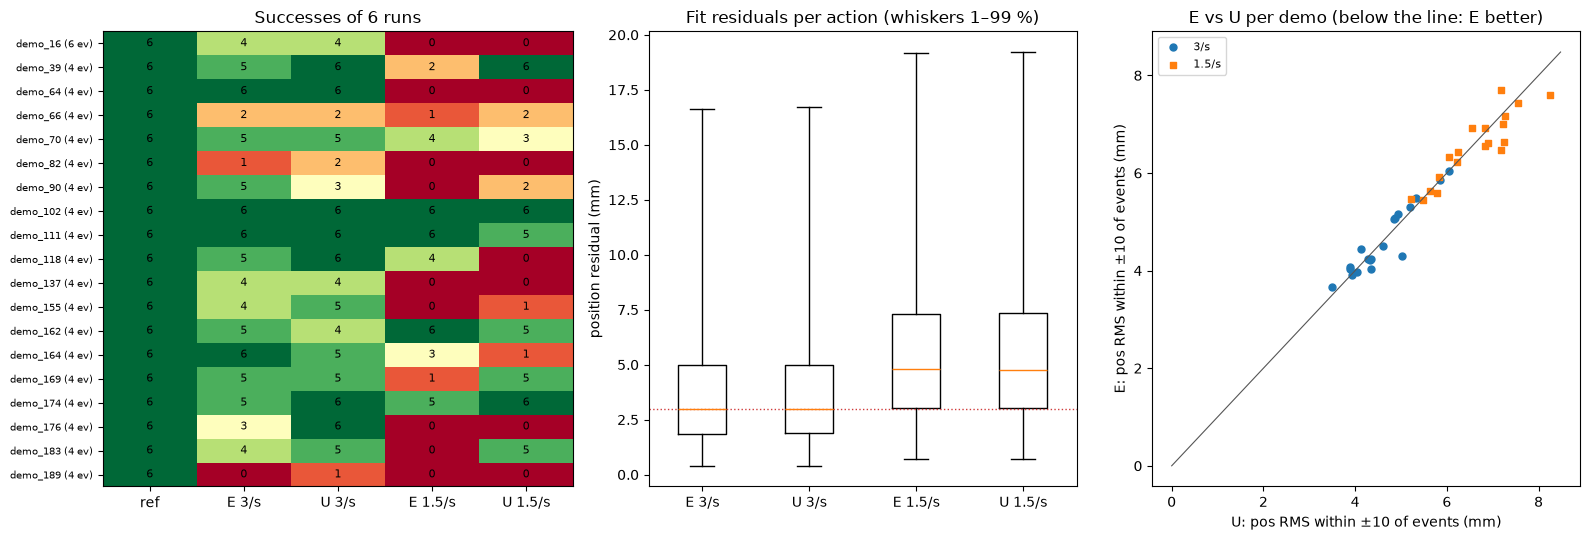

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.1, 1, 1]})
table = np.array([[REF_WINS[d]] + [CW[c][d] for c in CANDS] for d in ROBUST19])
im = axs[0].imshow(table, cmap="RdYlGn", vmin=0, vmax=6, aspect="auto")
for (i, j), val in np.ndenumerate(table):
    axs[0].text(j, i, val, ha="center", va="center", fontsize=8)
axs[0].set(xticks=range(5), xticklabels=["ref", *[label(*c) for c in CANDS]], yticks=range(19),
           yticklabels=[f"{d} ({len(INFO[d]['events'])} ev)" for d in ROBUST19], title="Successes of 6 runs")
axs[0].tick_params(axis="y", labelsize=7)
data_pos = [np.concatenate([RESID[c][d]["pos"] for d in ROBUST19]) for c in CANDS]
data_rot = [np.concatenate([RESID[c][d]["rot"] for d in ROBUST19]) for c in CANDS]
axs[1].boxplot(data_pos, tick_labels=[label(*c) for c in CANDS], showfliers=False, whis=(1, 99))
axs[1].axhline(3, color="#d03b3b", ls=":", lw=1)
axs[1].set(ylabel="position residual (mm)", title="Fit residuals per action (whiskers 1–99 %)")
for rho, marker in ((3, "o"), (1.5, "s")):
    e = [RESID["event", rho][d]["pos_ev"] for d in ROBUST19]
    u = [RESID["uniform", rho][d]["pos_ev"] for d in ROBUST19]
    axs[2].scatter(u, e, marker=marker, s=25, label=f"{rho:g}/s")
lim = [0, max(axs[2].get_xlim()[1], axs[2].get_ylim()[1])]
axs[2].plot(lim, lim, color="#555555", lw=0.8)
axs[2].set(xlabel="U: pos RMS within ±10 of events (mm)", ylabel="E: pos RMS within ±10 of events (mm)", title="E vs U per demo (below the line: E better)")
axs[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4.1 Videos

`scripts/render_side_by_side.py --task tool_hang` for demo_16, demo_102 and demo_189 (reference, E 3/s, U 3/s), in `docs/tool_hang/bezier-fit/videos/`. The video loop now calls `sim.forward()` after each step, as `read_state` and `screen_replay.py` do. Without that call, 2 of the 6 fit replays had a different outcome than the nominal screening run. In demo_189, E 3/s puts the tool on the stand base instead of on the hook.

**Result of H25.4: rejected; no detectable difference between E and U.** All 76 fits converge, but no candidate is as reliable as the reference (114 of 114 runs): at 3 segments/s E succeeds in 81 and U in 87 runs, at 1.5 segments/s in 38 and 47. Success falls with fewer segments, so the fit error matters. E and U have the same residuals (3/s: 5.2 mm, 0.16 deg RMS), and no paired test of E vs U reaches p < 0.05.

**Answers.** (1) Whole-demo cubic Bézier fits at 3 segments/s execute these Tool Hang trajectories in about three quarters of the runs, not reliably; at 1.5 segments/s in less than half. (2) Knots at the gripper events give no detectable benefit over uniform knots at the same K.

## 4.2 Follow-up: 6 segments/s on 5 failing demos

**Question (user).** Do more control points succeed? The 5 demos with the fewest successes at 3 segments/s (E + U) are fitted at 6 segments/s with E and U and replayed with the same protocol: demo_189, demo_82, demo_66, demo_16, demo_137. This is a small check, not a pass/fail test: success counts at 6/s are compared with 1.5 and 3/s and with the reference.

In [5]:
FAIL5 = ["demo_189", "demo_82", "demo_66", "demo_16", "demo_137"]
for v in ("event", "uniform"):
    runs6 = json.loads((SCREEN_DIR / f"h25_4_{v}_rho6.json").read_text())["runs"]
    CW[v, 6] = {d: sum(r["success_with_hold"] for r in runs6 if r["demo"] == d) for d in FAIL5}
    CPATHS[v, 6] = dict(np.load(SCREEN_DIR / f"h25_4_{v}_rho6.paths.npz"))
    with h5py.File(DATA / f"bezier_{v}_rho6.hdf5", "r") as f:
        CFITS[v, 6] = {d: {"actions": f[f"data/{d}/actions"][:], "ks": tuple(f[f"data/{d}/bezier"].attrs["ks"]),
                           "diag": json.loads(f[f"data/{d}/bezier"].attrs["diagnostics"])} for d in FAIL5}
ORDER = [(v, rho) for rho in (1.5, 3, 6) for v in ("event", "uniform")]
print(f"{'demo':9s} {'K@6':>4s}  ref " + " ".join(f"{label(*c):>8s}" for c in ORDER))
for d in FAIL5:
    print(f"{d:9s} {sum(CFITS['event', 6][d]['ks']):4d}  {REF_WINS[d]:3d} " + " ".join(f"{CW[c][d]:8d}" for c in ORDER))
print(f"{'total':9s} {'':4s}  {sum(REF_WINS[d] for d in FAIL5):3d} " + " ".join(f"{sum(CW[c][d] for d in FAIL5):8d}" for c in ORDER) + "   (of 30)")
for c in (("event", 6), ("uniform", 6)):
    res = [fit_residuals(c, d) for d in FAIL5]
    pos, rot = np.concatenate([r[0] for r in res]), np.concatenate([r[1] for r in res])
    dg = [CFITS[c][d]["diag"] for d in FAIL5]
    dp = [np.median(1e3 * np.linalg.norm(CPATHS[c][f"{d}_pos"] - REF_PATHS[f"{d}_pos"], axis=1)) for d in FAIL5]
    print(f"{label(*c)}: residual pos RMS {rms_(pos):.2f} mm (> 3 mm {np.mean(pos > 3):.0%}), rot RMS {rms_(rot):.3f} deg; "
          f"TRF status {sorted(set(x['status'] for x in dg))}, active max {max(x['active'] for x in dg)}; "
          f"achieved path vs reference, median per demo {np.median(dp):.1f} mm")

demo       K@6  ref  E 1.5/s  U 1.5/s    E 3/s    U 3/s    E 6/s    U 6/s
demo_189   155    6        0        0        0        1        3        4
demo_82    125    6        0        0        1        2        5        6
demo_66    138    6        1        2        2        2        4        5
demo_16    203    6        0        0        4        4        6        5
demo_137   122    6        0        0        4        4        6        6
total            30        1        2       11       13       24       26   (of 30)
E 6/s: residual pos RMS 4.97 mm (> 3 mm 34%), rot RMS 0.073 deg; TRF status [1], active max 0; achieved path vs reference, median per demo 0.2 mm
U 6/s: residual pos RMS 4.95 mm (> 3 mm 33%), rot RMS 0.075 deg; TRF status [1], active max 0; achieved path vs reference, median per demo 0.2 mm


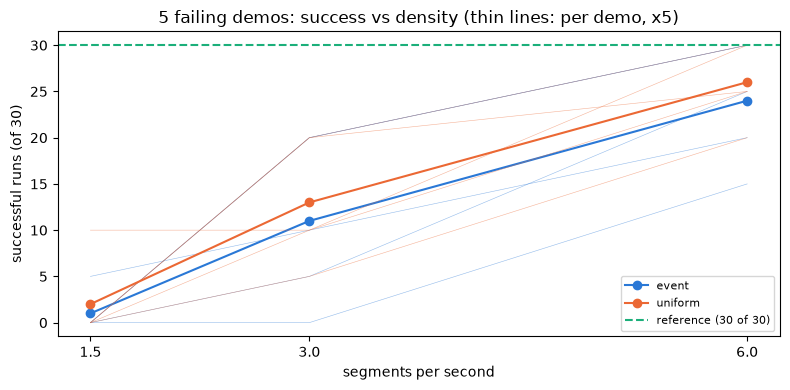

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
dens = [1.5, 3, 6]
for v, color in (("event", "#2a78d6"), ("uniform", "#eb6834")):
    ax.plot(dens, [sum(CW[v, r][d] for d in FAIL5) for r in dens], "o-", color=color, label=v)
    for d in FAIL5:
        ax.plot(dens, [CW[v, r][d] * 5 for r in dens], color=color, lw=0.4, alpha=0.5)
ax.axhline(30, color="#1baf7a", ls="--", label="reference (30 of 30)")
ax.set(xlabel="segments per second", ylabel="successful runs (of 30)", xticks=dens,
       title="5 failing demos: success vs density (thin lines: per demo, x5)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Result of section 4.2.** More control points help strongly: on the 5 failing demos, success rises from 1–2 (1.5/s) to 11–13 (3/s) to 24–26 of 30 runs (6/s), against 30 for the reference. The achieved grip-site path now stays within a median 0.2 mm of the reference. E and U stay equal. The position RMS stays near 5 mm because of the start jump at actions 1–2; elsewhere the residual is smaller (34 % of actions above 3 mm, against 50 % at 3/s).

---
# Part 5. Contact-weighted knot density (H25.6)

**Hypothesis H25.6.** At the same total K as 3 segments/s, segment durations h_k that put more segments near the precise parts raise the success of the 5 worst demos (demo_189, 82, 66, 16, 137) from the 3/s level (U: 13 of 30) to the 6/s uniform level (U: 26 of 30). Plan: `docs/H25_6_contact_density_plan.md`.

Two weight rules, both with a knot at every gripper event and the same K = Σ round(3 T_i) as E at 3/s:

- **release:** w = 3 in the last 2 s before every gripper release (frame insertion, tool hanging), 1 elsewhere.
- **speed:** w = 1 / (v + 2 cm/s), v = commanded grip-site speed, moving average over 5 steps.

Each phase gets segments in proportion to its weight integral (largest remainder, at least 1). Inside a phase, every segment covers an equal weight integral, so the density 1/h_k follows w. If a segment would be shorter than h_min = 0.15 s, w is capped from above (largest cap found by bisection).

## 5.1 Decoder with one duration per segment (H25.6.1)

`decode(c, h, t)`, `velocity(c, h, t)`, `fit(c0, h, ...)`, `initialize(p, r, events, h, ks)`, `position_lstsq(c, h, t, p)`. `segment_controls` did not change: it already used ρ_k = h_k / h_{k+1} at every knot. Part 2 (synthetic checks 2–8, including the Lift (5, 2) regression) is run again with the new API.

| # | Check | Pass if |
| --- | --- | --- |
| R1 | demo_16 E and U at 3/s, refit with the new API, vs the stored H25.4 fits | ≤ 1e-10 m and rad |
| S2 | synthetic curve with unequal h (ratios up to 4): `decode(τ_k)` = q_k | ≤ 1e-12 |
| S3a | one-sided velocities agree at every interior knot | ≤ 1e-9 |
| S3b | negative control ρ = 1: jump at every knot where h changes | > 0.1 |
| S3c | central FD (ε = 1e-8 s) vs one-sided velocity | ≤ 1e-6 |
| S5 | residual Jacobian vs central FD | relative ≤ 1e-6 |
| S6 | recovery of the known curve, tight tolerances | RMS ≤ 1e-9 |
| D1 | `place` with w = 1 gives equal h inside each phase | ≤ 1e-12 s |
| D2 | both rules on the 19 robust demos: Σ K_i = K, phase sums of h = T_i, min h ≥ h_min | exact; ≤ 1e-9 s; pass |

In [3]:
# R1: the new API reproduces the stored H25.4 fits of demo_16 at 3 segments/s.
# Part 2 reuses the name DATA for the synthetic fit data, so the dataset folder gets its own name here.
TH = ROOT / "data/robomimic/datasets/tool_hang/ph"
for variant in ("event", "uniform"):
    c, h, ks, _, decoded, diag = fit_demo(h5py.File(TH / "low_dim_abs_q0start.hdf5", "r")["data/demo_16/actions"][:], density=3.0, variant=variant)
    with h5py.File(TH / f"bezier_{variant}_rho3.hdf5", "r") as f:
        stored = f["data/demo_16/actions"][:]
    dp = np.linalg.norm(decoded[:, :3] - stored[:, :3], axis=1).max()
    dr = (Rotation.from_rotvec(decoded[:, 3:6]).inv() * Rotation.from_rotvec(stored[:, 3:6])).magnitude().max()
    print(f"{variant}: K = {len(h)}, {diag['seconds']:.0f} s")
    record(f"R1 {variant}: |new - stored| position (m)", dp, 1e-10)
    record(f"R1 {variant}: |new - stored| rotation (rad)", dr, 1e-10)

event: K = 101, 22 s
R1 event: |new - stored| position (m): 2.024e-15 (limit <= 1e-10) pass
R1 event: |new - stored| rotation (rad): 2.315e-15 (limit <= 1e-10) pass


uniform: K = 101, 11 s
R1 uniform: |new - stored| position (m): 2.208e-15 (limit <= 1e-10) pass
R1 uniform: |new - stored| rotation (rad): 1.495e-15 (limit <= 1e-10) pass


In [15]:
# S2-S6: synthetic curve with unequal segment durations.
from bezier_rfm.fitting.density import place, place_capped, release_weight, speed_weight

rng_s = np.random.default_rng(1)
HS = np.array([0.4, 0.1, 0.25, 0.4, 0.15, 0.6, 0.3, 0.3, 0.2, 0.45])
KS_S = len(HS)
TAU_S = np.asarray(knot_times(HS))
print("h (s):", HS, "\nrho at interior knots:", HS[:-1] / HS[1:])
qp = np.linspace([0.0, 0.0, 1.0], [-0.1, 0.05, 0.85], KS_S + 1) + 0.02 * rng_s.normal(size=(KS_S + 1, 3))
qr = Rotation.from_rotvec(0.3 * rng_s.normal(size=(KS_S + 1, 3))).as_matrix()
TRUE_S = Controls(qp, qr, qp + 0.03 * rng_s.normal(size=(KS_S + 1, 3)), qr @ Rotation.from_rotvec(0.15 * rng_s.normal(size=(KS_S + 1, 3))).as_matrix())

p_k, r_k = decode(TRUE_S, HS, jnp.asarray(TAU_S))
record("S2 |decode(tau_k) - q_k|", max(np.abs(np.asarray(p_k) - qp).max(), np.abs(np.asarray(r_k) - qr).max()), 1e-12)

POS_S, ROT_S = segment_controls(TRUE_S, jnp.asarray(HS))
NPOS_S, NROT_S = segment_controls(TRUE_S, jnp.ones(KS_S))


def seg_vel(pos, rot, k, u):
    """Return [linear, angular] velocity in seconds of segment k at local parameter u.

    Args:
        pos (jnp.ndarray): Control positions, shape (K, 4, 3).
        rot (jnp.ndarray): Control rotations, shape (K, 4, 3, 3).
        k (int): Segment index.
        u (float): Local parameter.

    Returns:
        np.ndarray: Velocity, shape (6,).
    """
    f = lambda x: segment_point(pos[k], rot[k], x)
    (_, r), (dp, dr) = f(u), jax.jacfwd(f)(u)
    return np.r_[dp, so3.vee(r.T @ dr)] / HS[k]


c1, fd, naive = [], [], []
for k in range(1, KS_S):
    left, right = seg_vel(POS_S, ROT_S, k - 1, 1.0), seg_vel(POS_S, ROT_S, k, 0.0)
    (pa, pb), (ra, rb) = (np.asarray(a) for a in decode(TRUE_S, HS, jnp.array([TAU_S[k] - EPS, TAU_S[k] + EPS])))
    diff = np.r_[(pb - pa) / (2 * EPS), so3.log(ra.T @ rb) / (2 * EPS)]
    c1.append(np.abs(left - right).max())
    fd.append(np.abs(diff - left).max())
    if HS[k - 1] != HS[k]:
        naive.append(np.abs(seg_vel(NPOS_S, NROT_S, k - 1, 1.0) - seg_vel(NPOS_S, NROT_S, k, 0.0)).max())
record("S3a |left - right velocity| at interior knots", max(c1), 1e-9)
record("S3b naive jump where h changes, smallest", min(naive), 0.1, larger_passes=True)
record("S3c |central FD - one-sided velocity|", max(fd), 1e-6)

NSS = int(round(HS.sum() / CONTROL_DT)) + 1
TSS = CONTROL_DT * np.arange(NSS)
PT_S, RT_S = (np.asarray(a) for a in decode(TRUE_S, HS, jnp.asarray(TSS)))
DATA_S = (np.stack([qp[0], qp[-1]]), np.stack([qr[0], qr[-1]]), HS, TSS[1:-1], PT_S[1:-1], RT_S[1:-1], 1 / np.sqrt(NSS))
C0_S = perturb_controls(TRUE_S, 0.01, 0.05)
anchors = split_free(C0_S)
x0 = 0.01 * rng_s.normal(size=12 * KS_S)
J = np.asarray(jacobian(x0, *anchors, *DATA_S))
worst = 0.0
for _ in range(10):
    d = rng_s.normal(size=x0.size)
    d /= np.linalg.norm(d)
    fdj = (np.asarray(residuals(x0 + 1e-6 * d, *anchors, *DATA_S)) - np.asarray(residuals(x0 - 1e-6 * d, *anchors, *DATA_S))) / 2e-6
    worst = max(worst, np.linalg.norm(fdj - J @ d) / np.linalg.norm(J @ d))
record("S5 relative |J d - FD|", worst, 1e-6)

fitted, diag = fit(C0_S, HS, TSS[1:-1], PT_S[1:-1], RT_S[1:-1], NSS, trf={"gtol": 1e-15, "ftol": 1e-15, "xtol": 1e-15})
p_f, r_f = (np.asarray(a) for a in decode(fitted, HS, jnp.asarray(TSS)))
rot_f = np.asarray(jax.vmap(so3.log)(np.swapaxes(r_f, 1, 2) @ RT_S))
record("S6 RMS residual after recovery", max(np.sqrt(np.mean(np.sum((p_f - PT_S) ** 2, 1))), np.sqrt(np.mean(np.sum(rot_f**2, 1)))), 1e-9)

h (s): [0.4  0.1  0.25 0.4  0.15 0.6  0.3  0.3  0.2  0.45] 
rho at interior knots: [4.         0.4        0.625      2.66666667 0.25       2.
 1.         1.5        0.44444444]
S2 |decode(tau_k) - q_k|: 3.331e-16 (limit <= 1e-12) pass


S3a |left - right velocity| at interior knots: 2.665e-15 (limit <= 1e-09) pass
S3b naive jump where h changes, smallest: 0.7754 (limit >= 0.1) pass
S3c |central FD - one-sided velocity|: 9.575e-07 (limit <= 1e-06) pass


S5 relative |J d - FD|: 2.962e-10 (limit <= 1e-06) pass


S6 RMS residual after recovery: 1.268e-16 (limit <= 1e-09) pass


In [16]:
# D1, D2: knot placement on the 19 robust demos.
ROBUST19 = sorted((d for d in KEYS if sum(r["success_with_hold"] for r in SCREEN["runs"] if r["demo"] == d) == 6), key=lambda d: int(d[5:]))
with h5py.File(TH / "low_dim_abs_q0start.hdf5", "r") as f:
    CMD19 = {d: f[f"data/{d}/actions"][:] for d in ROBUST19}
RULES = {"release": lambda a, ev: release_weight(a, ev), "speed": lambda a, ev: speed_weight(a)}
H_MIN = 0.15
PLACED = {}
d1, d2_phase, d2_ok = 0.0, 0.0, True
for d, a in CMD19.items():
    ev = (np.flatnonzero(np.diff(a[:, 6])) + 1).tolist()
    bounds = np.array([0, *ev, len(a) - 1])
    dur = CONTROL_DT * np.diff(bounds)
    k = sum(max(1, int(round(3.0 * x))) for x in dur)
    h1, ks1 = place(np.ones(len(a)), ev, k)
    d1 = max(d1, np.abs(h1 - np.asarray(phase_h(dur, ks1))).max())
    for rule, wf in RULES.items():
        w = wf(a, ev)
        h, ks, cap = place_capped(w, ev, k, H_MIN)
        PLACED[rule, d] = {"h": h, "ks": ks, "cap": cap, "w": w, "events": ev, "bounds": bounds, "k": k}
        sums = np.add.reduceat(h, np.r_[0, np.cumsum(ks)[:-1]])
        d2_phase = max(d2_phase, np.abs(sums - dur).max())
        d2_ok &= sum(ks) == k and h.min() >= H_MIN - 1e-12
record("D1 |place(w = 1) - equal h per phase| (s)", d1, 1e-12)
record("D2a |phase sum of h - T_i| (s)", d2_phase, 1e-9)
record("D2b sum K_i = K and min h >= h_min (1 = pass)", float(d2_ok), 1.0, larger_passes=True)
for rule in RULES:
    caps = [PLACED[rule, d]["cap"] / PLACED[rule, d]["w"].max() for d in ROBUST19]
    at_min = np.mean(np.concatenate([np.isclose(PLACED[rule, d]["h"], H_MIN, atol=1e-6) for d in ROBUST19]))
    print(f"{rule}: weight cap / max weight median {np.median(caps):.2f} (range {min(caps):.2f}-{max(caps):.2f}); segments at h_min {100 * at_min:.0f} %")

D1 |place(w = 1) - equal h per phase| (s): 9.492e-15 (limit <= 1e-12) pass
D2a |phase sum of h - T_i| (s): 2.776e-15 (limit <= 1e-09) pass
D2b sum K_i = K and min h >= h_min (1 = pass): 1 (limit >= 1) pass
release: weight cap / max weight median 1.00 (range 0.90-1.00); segments at h_min 7 %
speed: weight cap / max weight median 0.97 (range 0.72-1.00); segments at h_min 1 %


In [17]:
part5 = {k: v for k, v in CHECKS.items() if k.split()[0] in ("R1", "S2", "S3a", "S3b", "S3c", "S5", "S6", "D1", "D2a", "D2b") or k[0] in "2345678"}
for name, (value, limit, ok) in part5.items():
    print(f"{'pass' if ok else 'FAIL'}  {name}: {value:.2e} (limit {limit:.0e})")
print(f"\n{sum(ok for *_, ok in part5.values())} of {len(part5)} checks pass")

pass  2a |decode(tau_k) - q_k|: 1.67e-16 (limit 1e-12)
pass  2b |tau at event knots and ends - cumulative sums|: 8.88e-16 (limit 1e-12)
pass  3a |left - right velocity| at interior knots: 2.22e-15 (limit 1e-09)
pass  3b naive jump at event knots, smallest: 3.20e-01 (limit 1e-01)
pass  3b naive jump at other knots, largest: 2.22e-15 (limit 1e-09)
pass  3c |central FD - one-sided velocity|, eps = 1e-8: 3.71e-07 (limit 1e-06)
pass  4 |autodiff - analytic end velocity|: 2.89e-15 (limit 1e-10)
pass  5 relative |J d - FD|: 3.98e-10 (limit 1e-06)
pass  6a RMS residual, tight tolerances: 1.12e-16 (limit 1e-09)
pass  6b |q_0, q_K fitted - true|: 0.00e+00 (limit 0e+00)
pass  7a Lift regression, position (m): 4.44e-16 (limit 1e-10)
pass  7b Lift regression, rotation (rad): 5.63e-16 (limit 1e-10)
pass  7c Lift regression, gripper columns differ: 0.00e+00 (limit 0e+00)
pass  8a U: spread of h: 0.00e+00 (limit 0e+00)
pass  8b U: |tau - k h|: 8.88e-16 (limit 1e-12)
pass  8c U: |controls - rho = 1 con

**Result of section 5.1 (H25.6.1): confirmed.** All 29 checks pass. With the new API, the demo_16 E and U fits at 3/s equal the stored H25.4 fits (≤ 2.3e-15), and the Lift (5, 2) fits equal the stored H24 fits. On a synthetic curve with ρ from 0.25 to 4, the velocity in seconds is continuous at every knot (2.7e-15), and the ρ = 1 control jumps by at least 0.78. Checks 2b and 8b now use 1e-12 instead of 0, because τ is the cumulative sum of h (difference 8.9e-16). S3c (9.6e-7) is near its limit because the 0.1 s segment has a large acceleration, so the FD truncation error is larger. Both rules meet h_min on all 19 demos. The release rule caps its weight in a few demos (7 % of segments at h_min). The speed rule puts 1 % of segments at h_min.

## 5.2 Segment durations across demos (H25.6.2)

**Question.** Do similar parts of different demos get similar h_k? A policy must later predict log h_k from observations, so the targets must not be noisy across similar demos.

Plots for the 19 robust demos and both rules:
1. Density 1/h_k against time, one line per demo, gripper events marked (closes red, releases blue).
2. The same against a normalized phase coordinate: phase index + (time in phase / phase duration). Only the 18 four-event demos; demo_16 has 7 phases.
3. Median and 10–90 % band of log h_k per normalized-phase bin (10 bins per phase).
4. demo_16: commanded speed and the knot times of both rules.

Flag (information only): a bin where the 10–90 % band of h_k is wider than a factor of 2 and the median density is above the overall median.

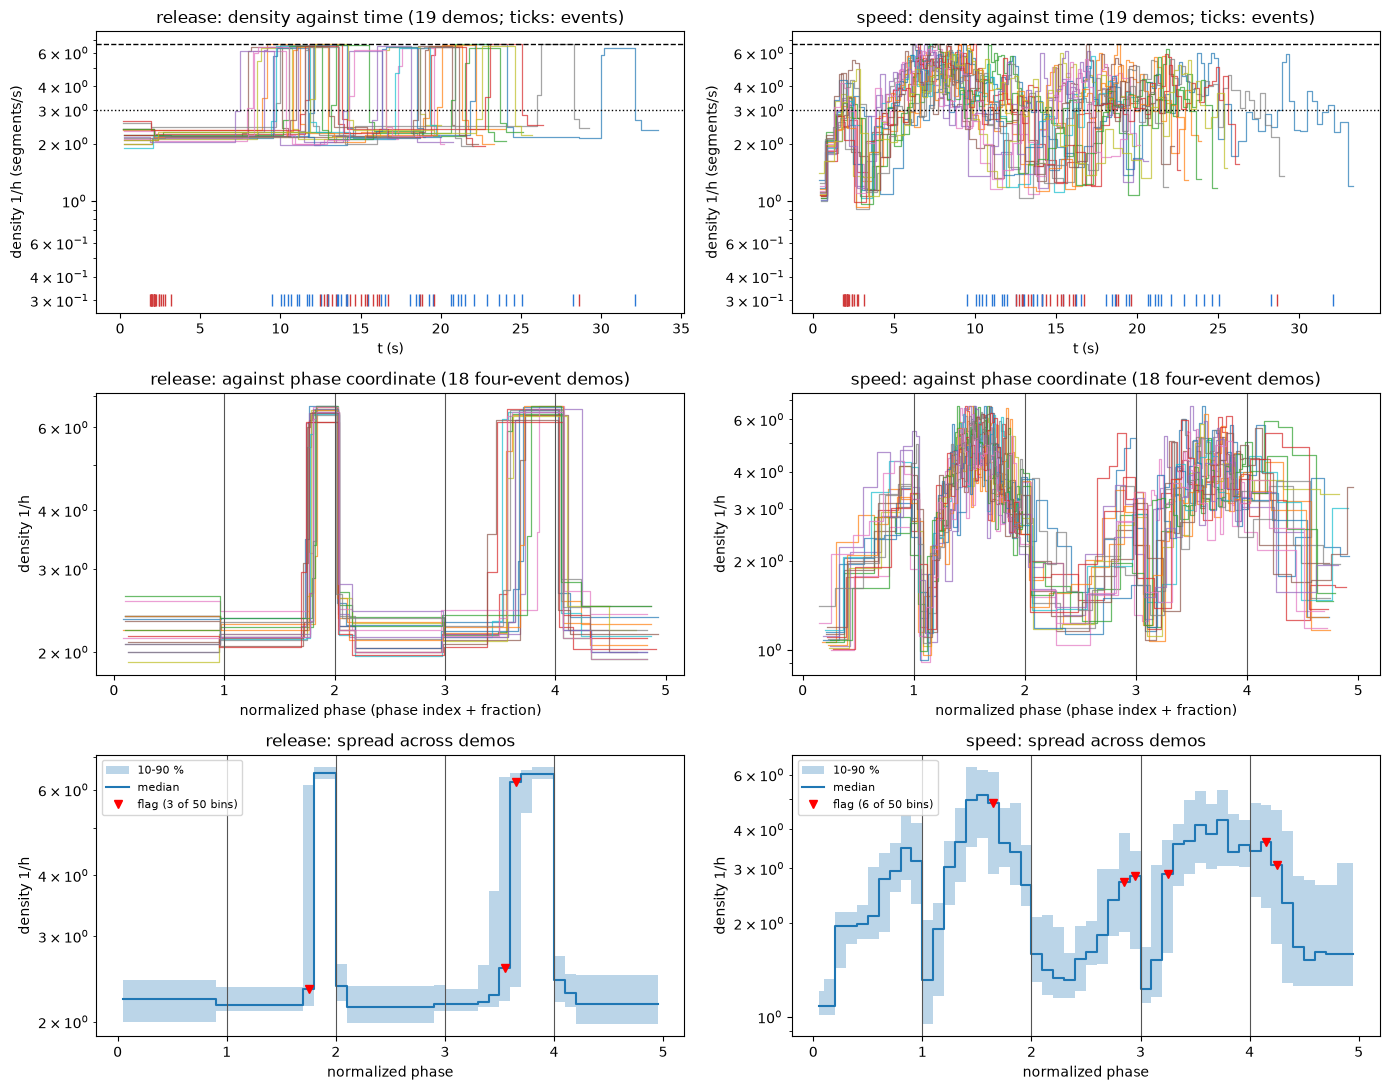

release: median 90/10 ratio 1.19; per phase [1.22 1.12 1.19 1.17 1.26]; flagged bins 3
speed: median 90/10 ratio 1.73; per phase [1.48 1.77 1.66 1.66 2.22]; flagged bins 6


In [18]:
def segment_table(rule, d):
    """Return the mid time, density and normalized phase coordinate of every segment.

    Args:
        rule (str): Weight rule.
        d (str): Demo name.

    Returns:
        tuple: Mid times (s), densities (1/s) and phase coordinates, each shape (K,).
    """
    pl = PLACED[rule, d]
    tau = np.asarray(knot_times(pl["h"]))
    mid = 0.5 * (tau[1:] + tau[:-1])
    edges = CONTROL_DT * pl["bounds"]
    phase = np.clip(np.searchsorted(edges, mid, side="right") - 1, 0, len(edges) - 2)
    return mid, 1.0 / pl["h"], phase + (mid - edges[phase]) / np.diff(edges)[phase]


FOUR = [d for d in ROBUST19 if len(PLACED["release", d]["events"]) == 4]
fig, axs = plt.subplots(3, 2, figsize=(14, 11))
for j, rule in enumerate(RULES):
    ax = axs[0, j]
    for d in ROBUST19:
        mid, dens, _ = segment_table(rule, d)
        line, = ax.step(mid, dens, where="mid", lw=0.9, alpha=0.7)
        a = CMD19[d]
        for e in PLACED[rule, d]["events"]:
            ax.plot(CONTROL_DT * e, 0.3, "|", ms=8, color=COLORS["open"] if a[e, 6] < a[e - 1, 6] else COLORS["close"])
    ax.set(xlabel="t (s)", ylabel="density 1/h (segments/s)", yscale="log", title=f"{rule}: density against time (19 demos; ticks: events)")
    ax.axhline(3.0, color="k", ls=":", lw=1)
    ax.axhline(1 / H_MIN, color="k", ls="--", lw=1)

    ax = axs[1, j]
    for d in FOUR:
        _, dens, x = segment_table(rule, d)
        ax.step(x, dens, where="mid", lw=0.9, alpha=0.7)
    ax.set(xlabel="normalized phase (phase index + fraction)", ylabel="density 1/h", yscale="log", title=f"{rule}: against phase coordinate (18 four-event demos)")

    ax = axs[2, j]
    bins = np.linspace(0, 5, 51)
    cols = []
    for d in FOUR:
        _, dens, x = segment_table(rule, d)
        # Density at bin centres: each bin takes the segment that covers its centre.
        cols.append(dens[np.clip(np.searchsorted(x, 0.5 * (bins[1:] + bins[:-1])) , 0, len(x) - 1)])
    cols = np.array(cols)
    med, lo, hi = np.median(cols, 0), np.percentile(cols, 10, 0), np.percentile(cols, 90, 0)
    centres = 0.5 * (bins[1:] + bins[:-1])
    ax.fill_between(centres, lo, hi, step="mid", alpha=0.3, label="10-90 %")
    ax.step(centres, med, where="mid", lw=1.5, label="median")
    flag = (hi / lo > 2) & (med > np.median(med))
    ax.plot(centres[flag], med[flag], "rv", label=f"flag ({flag.sum()} of {len(flag)} bins)")
    ax.set(xlabel="normalized phase", ylabel="density 1/h", yscale="log", title=f"{rule}: spread across demos")
    ax.legend(fontsize=8)
    SPREAD = globals().setdefault("SPREAD", {})
    SPREAD[rule] = {"ratio_median": float(np.median(hi / lo)), "flags": int(flag.sum()), "per_phase_ratio": [float(np.median((hi / lo)[i * 10:(i + 1) * 10])) for i in range(5)]}
for ax in axs[1:].flat:
    for p in range(1, 5):
        ax.axvline(p, color="#555555", lw=0.8)
fig.tight_layout()
plt.show()
for rule, s in SPREAD.items():
    print(f"{rule}: median 90/10 ratio {s['ratio_median']:.2f}; per phase {np.round(s['per_phase_ratio'], 2)}; flagged bins {s['flags']}")

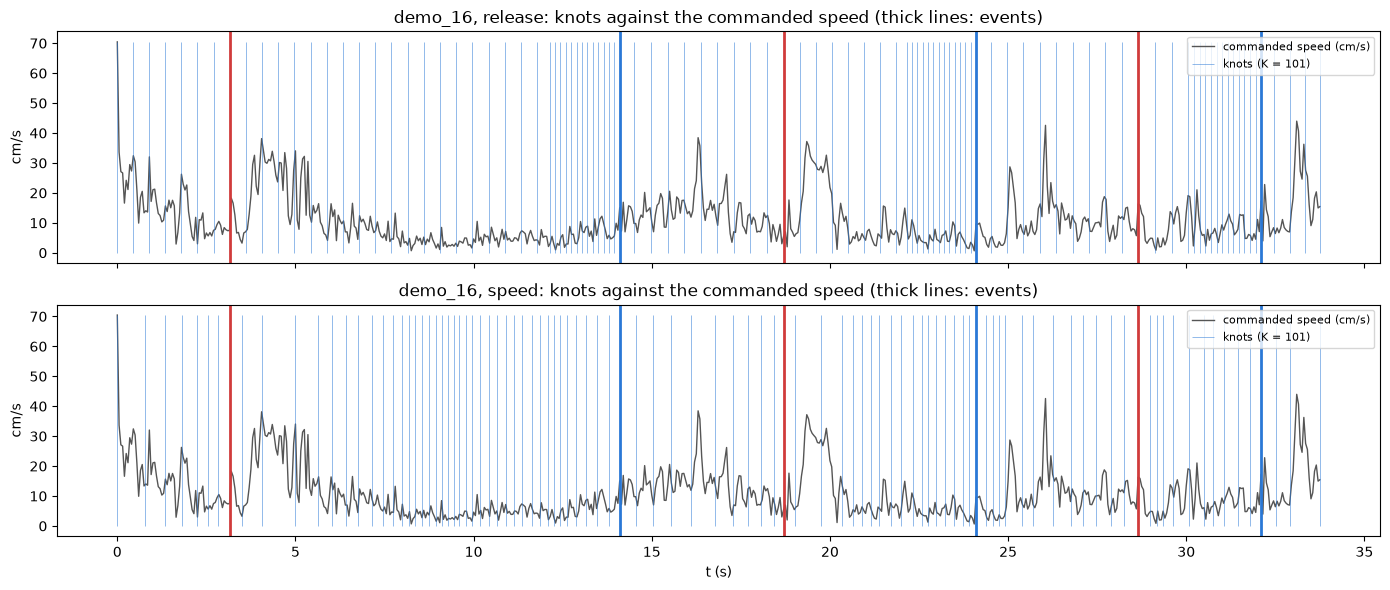

In [19]:
a = CMD19["demo_16"]
v = np.linalg.norm(np.gradient(a[:, :3], CONTROL_DT, axis=0), axis=1)
t = CONTROL_DT * np.arange(len(a))
fig, axs = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, rule in zip(axs, RULES):
    ax.plot(t, 100 * v, color="#555555", lw=1, label="commanded speed (cm/s)")
    tau = np.asarray(knot_times(PLACED[rule, "demo_16"]["h"]))
    ax.vlines(tau, 0, 100 * v.max(), color="#2a78d6", lw=0.6, alpha=0.6, label=f"knots (K = {len(tau) - 1})")
    for e in PLACED[rule, "demo_16"]["events"]:
        ax.axvline(CONTROL_DT * e, color=COLORS["open"] if a[e, 6] < a[e - 1, 6] else COLORS["close"], lw=2)
    ax.set(ylabel="cm/s", title=f"demo_16, {rule}: knots against the commanded speed (thick lines: events)")
    ax.legend(fontsize=8, loc="upper right")
axs[-1].set(xlabel="t (s)")
fig.tight_layout()
plt.show()

**Result of section 5.2 (H25.6.2).** Similar parts of different demos get similar h_k for both rules. The release rule is more uniform across demos than the speed rule.

- **release:** about 6.5 segments/s in the 2 s before each release (near the 1/h_min limit), and about 2.2/s elsewhere. Across demos, the 90/10 ratio of the density is 1.19 (median). The 3 flagged bins are at the window edges, where a step falls at slightly different phase fractions; they are not noise.
- **speed:** the density follows the phases: about 1–2/s in the reach phases 1 and 3, and 3–6/s in the carry phases 2 and 4. But the peak is in the middle of phase 2, not at its end. The 90/10 ratio is 1.73 (median) and 2.2 in phase 5; 6 bins are flagged. The fast start jump (actions 1–2) gets only about 1 segment/s.
- So the two rules put the segments in different places: release puts them at the end of phases 2 and 4, speed spreads them over the whole of phases 2 and 4.

## 5.3 Replay screening of the weighted placements (H25.6.3)

The 5 worst demos of H25.4 (demo_189, 82, 66, 16, 137) are fitted with the release and speed rules at the same K as 3/s, and screened with the H25.4 protocol (nominal run + 5 runs with 0.2 mm / 0.2 mrad noise, 60 hold steps).

**Pass rule (per rule):** at least 24 of 30 runs, and more than U at 3/s in a paired sign test (p < 0.05) over the 30 (demo, seed) runs. Rejected at 17 or fewer. Inconclusive in between.

Report: successes per demo next to the baselines; residuals overall, within ±10 steps of each event, and in the 2 s before each release; fraction of actions above 3 mm; median achieved grip-site distance to the reference (nominal runs).

In [4]:
from scipy.stats import binomtest

FAIL5 = ["demo_189", "demo_82", "demo_66", "demo_16", "demo_137"]
SDIR = ROOT / "docs/tool_hang/screening"
CANDS6 = {"ref": "h25_4_reference", "U 3/s": "h25_4_uniform_rho3", "E 3/s": "h25_4_event_rho3", "release 3/s": "h25_6_release_rho3",
          "speed 3/s": "h25_6_speed_rho3", "E 6/s": "h25_4_event_rho6", "U 6/s": "h25_4_uniform_rho6"}
FILES6 = {"U 3/s": "bezier_uniform_rho3", "E 3/s": "bezier_event_rho3", "release 3/s": "bezier_release_rho3", "speed 3/s": "bezier_speed_rho3",
          "E 6/s": "bezier_event_rho6", "U 6/s": "bezier_uniform_rho6"}
OUT, PATHS6, FITS6 = {}, {}, {}
for c, stem in CANDS6.items():
    runs = json.loads((SDIR / f"{stem}.json").read_text())["runs"]
    OUT[c] = {(r["demo"], r["seed"]): r["success_with_hold"] for r in runs if r["demo"] in FAIL5}
    PATHS6[c] = dict(np.load(SDIR / f"{stem}.paths.npz"))
for c, stem in FILES6.items():
    with h5py.File(TH / f"{stem}.hdf5", "r") as f:
        FITS6[c] = {d: {"actions": f[f"data/{d}/actions"][:], "attrs": dict(f[f"data/{d}/bezier"].attrs)} for d in FAIL5}
with h5py.File(TH / "low_dim_abs_q0start.hdf5", "r") as f:
    CMD5 = {d: f[f"data/{d}/actions"][:] for d in FAIL5}

wins5 = lambda c, d: sum(v for (dd, _), v in OUT[c].items() if dd == d)
print(f"{'demo':9s} {'K':>4s} " + " ".join(f"{c:>11s}" for c in CANDS6))
for d in FAIL5:
    print(f"{d:9s} {len(FITS6['release 3/s'][d]['attrs']['h']):4d} " + " ".join(f"{wins5(c, d):11d}" for c in CANDS6))
print(f"{'total':9s} {'':4s} " + " ".join(f"{sum(OUT[c].values()):11d}" for c in CANDS6) + "   (of 30)")

for c in ("release 3/s", "speed 3/s"):
    better = sum(OUT[c][k] and not OUT["U 3/s"][k] for k in OUT[c])
    worse = sum(OUT["U 3/s"][k] and not OUT[c][k] for k in OUT[c])
    p = binomtest(better, better + worse, 0.5, alternative="greater").pvalue if better + worse else 1.0
    total = sum(OUT[c].values())
    verdict = "pass" if total >= 24 and p < 0.05 else ("rejected" if total <= 17 else "inconclusive")
    print(f"{c}: {total} of 30; vs U 3/s: {better} better, {worse} worse runs, sign test p = {p:.3g} -> {verdict}")
    record(f"H25.6.3 {c}: successes of 30", total, 24, larger_passes=True)
    record(f"H25.6.3 {c}: sign test p vs U 3/s", p, 0.05)

demo         K         ref       U 3/s       E 3/s release 3/s   speed 3/s       E 6/s       U 6/s
demo_189    77           6           1           0           4           1           3           4
demo_82     63           6           2           1           3           4           5           6
demo_66     69           6           2           2           3           5           4           5
demo_16    101           6           4           4           5           5           6           5
demo_137    61           6           4           4           1           6           6           6
total                   30          13          11          16          21          24          26   (of 30)
release 3/s: 16 of 30; vs U 3/s: 8 better, 5 worse runs, sign test p = 0.291 -> rejected
H25.6.3 release 3/s: successes of 30: 16 (limit >= 24) FAIL
H25.6.3 release 3/s: sign test p vs U 3/s: 0.2905 (limit <= 0.05) FAIL
speed 3/s: 21 of 30; vs U 3/s: 11 better, 3 worse runs, sign test p = 0.0287 

In [5]:
def windows(d, n):
    """Return masks of the actions within ±10 steps of an event and in the 2 s before a release.

    Args:
        d (str): Demonstration name.
        n (int): Number of actions.

    Returns:
        tuple: Event-window mask and release-window mask, each shape (n,).
    """
    a = CMD5[d]
    ev = np.flatnonzero(np.diff(a[:, 6])) + 1
    m_ev, m_rel = np.zeros(n, bool), np.zeros(n, bool)
    for e in ev:
        m_ev[max(e - 10, 0): e + 11] = True
        if a[e, 6] < a[e - 1, 6]:
            m_rel[max(e - 40, 0): e + 1] = True
    return m_ev, m_rel


rms5 = lambda x: float(np.sqrt(np.mean(x**2)))
print(f"{'candidate':12s} {'pos RMS':>8s} {'>3 mm':>6s} {'rot RMS':>8s} {'ev pos':>7s} {'rel pos':>8s} {'rel >3mm':>8s} {'path med':>9s}")
RES6 = {}
for c in FILES6:
    pos, rot, pev, prel, path = [], [], [], [], []
    for d in FAIL5:
        dec, cmd = FITS6[c][d]["actions"], CMD5[d]
        p_ = 1e3 * np.linalg.norm(dec[:, :3] - cmd[:, :3], axis=1)
        r_ = np.degrees((Rotation.from_rotvec(dec[:, 3:6]).inv() * Rotation.from_rotvec(cmd[:, 3:6])).magnitude())
        m_ev, m_rel = windows(d, len(p_))
        pos.append(p_); rot.append(r_); pev.append(p_[m_ev]); prel.append(p_[m_rel])
        path.append(np.median(1e3 * np.linalg.norm(PATHS6[c][f"{d}_pos"] - PATHS6["ref"][f"{d}_pos"], axis=1)))
    pos, rot, pev, prel = (np.concatenate(x) for x in (pos, rot, pev, prel))
    RES6[c] = {"pos": pos, "path": path}
    print(f"{c:12s} {rms5(pos):6.2f}mm {np.mean(pos > 3):6.0%} {rms5(rot):6.3f}deg {rms5(pev):5.2f}mm {rms5(prel):6.2f}mm {np.mean(prel > 3):8.0%} "
          f"{np.median(path):7.2f}mm")

candidate     pos RMS  >3 mm  rot RMS  ev pos  rel pos rel >3mm  path med
U 3/s          5.72mm    52%  0.165deg  4.41mm   2.97mm      35%    0.55mm
E 3/s          5.73mm    53%  0.165deg  4.50mm   3.00mm      34%    0.55mm
release 3/s    6.27mm    58%  0.234deg  4.84mm   2.15mm      14%    1.03mm
speed 3/s      6.70mm    57%  0.336deg  5.11mm   2.96mm      29%    0.96mm
E 6/s          4.97mm    34%  0.073deg  3.35mm   2.15mm      15%    0.19mm
U 6/s          4.95mm    33%  0.075deg  3.23mm   2.10mm      12%    0.22mm


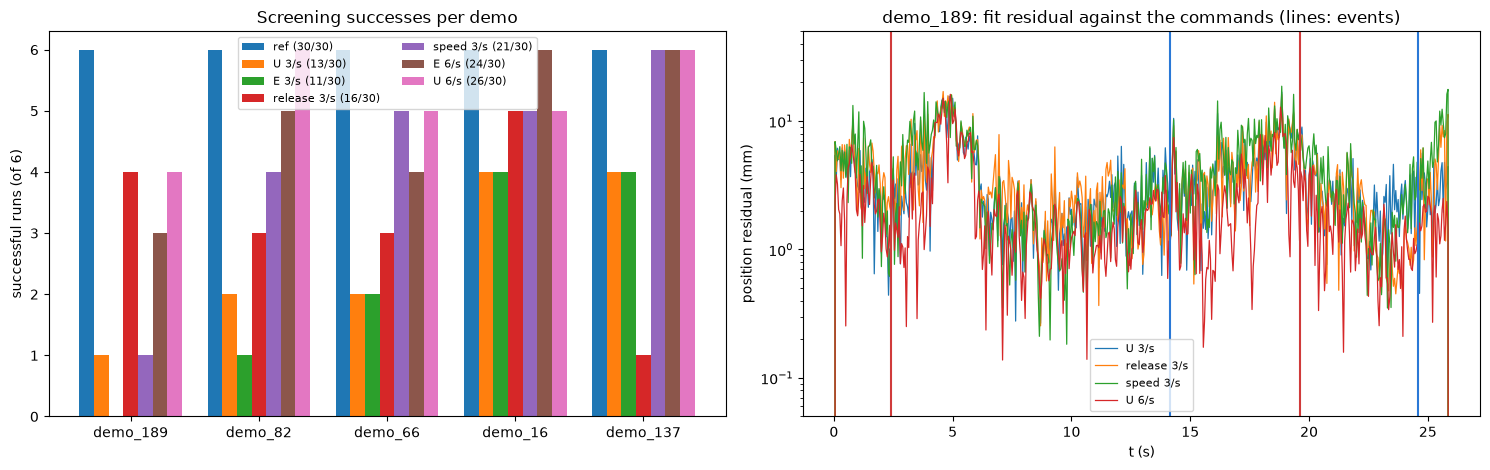

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
order = list(CANDS6)
xs = np.arange(len(FAIL5))
wd = 0.8 / len(order)
for i, c in enumerate(order):
    axs[0].bar(xs + (i - len(order) / 2 + 0.5) * wd, [wins5(c, d) for d in FAIL5], wd, label=f"{c} ({sum(OUT[c].values())}/30)")
axs[0].set(xticks=xs, xticklabels=FAIL5, ylabel="successful runs (of 6)", title="Screening successes per demo")
axs[0].legend(fontsize=8, ncol=2)
d = "demo_189"
t = CONTROL_DT * np.arange(len(CMD5[d]))
for c in ("U 3/s", "release 3/s", "speed 3/s", "U 6/s"):
    dec = FITS6[c][d]["actions"]
    axs[1].plot(t, 1e3 * np.linalg.norm(dec[:, :3] - CMD5[d][:, :3], axis=1), lw=0.9, label=c)
a = CMD5[d]
for e in np.flatnonzero(np.diff(a[:, 6])) + 1:
    axs[1].axvline(CONTROL_DT * e, color=COLORS["open"] if a[e, 6] < a[e - 1, 6] else COLORS["close"], lw=1.5)
axs[1].set(xlabel="t (s)", ylabel="position residual (mm)", yscale="log", ylim=(0.05, 50), title=f"{d}: fit residual against the commands (lines: events)")
axs[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Result of section 5.3 (H25.6.3).** speed: inconclusive; release: rejected. Neither rule reaches the 6/s level (24–26 of 30) at the K of 3/s.

- **speed:** 21 of 30 runs, against 13 for U 3/s (11 runs better, 3 worse, sign test p = 0.029). It is clearly better than U 3/s but below the 24 needed.
- **release:** 16 of 30 runs (8 better, 5 worse, p = 0.29). It gains on demo_189 (4 of 6) but loses on demo_137 (1 of 6, against 4).
- **Residuals do not predict success here.** release makes the residual in the 2 s before releases as small as at 6/s (2.15 mm RMS, 14 % above 3 mm). But its overall residual is larger (6.3 mm, 0.23°), and its success is lower than speed. speed has the largest overall residual (6.7 mm RMS, 0.34°) but the most successes.
- So segments over all of the slow carry phases help more than extra segments only near the release. Both rules have a median achieved-path distance to the reference of about 1 mm, against 0.55 mm for U 3/s and 0.2 mm at 6/s, because they take segments away from the fast parts.
- Caveat: 30 runs per rule and a chaotic task. A difference of 3–5 runs is near the noise level.